# Algoritmo de Aprendizaje Social por Imitación de Comportamientos de Movimiento

## 1. Inicialización del Enjambre
- Configurar el grupo de robots (ej. plataformas físicas o simuladas en ARGoS3) dentro del entorno de experimentación[cite: 1].
- Definir los comportamientos de movimiento (patrones de trayectorias específicos, tales como polígonos)[cite: 1].
- Asignar los roles dentro del enjambre: establecer qué individuos actuarán como **robots maestros** y cuál operará como el **robot aprendiz**[cite: 1].

## 2. Señalización e Inicio del Comportamiento
- Los robots maestros inician su comportamiento emitiendo señales de colores mediante sus LEDs, indicando de forma local el comienzo de la ejecución del comportamiento[cite: 1].

## 3. Percepción y Búsqueda Local
- El robot aprendiz revisa su entorno inmediato utilizando su cámara omnidireccional para detectar las señales de colores, identificando así a los maestros activos a su alrededor[cite: 1].

## 4. Observación del comportamiento de movimiento
- Los robots maestros ejecutan de forma descentralizada sus patrones de trayectorias predefinidos[cite: 1].
- Durante la ejecución, el robot aprendiz rastrea a sus pares, extrayendo información puramente local (como distancia, ángulo y color) y registrando los cambios de posición relativa a lo largo del tiempo[cite: 1].

## 5. Finalización del Comportamiento Maestro
- Al completar su patrón de trayectoria, los robots maestros modifican sus señales visuales (LEDs) para notificar la culminación del ciclo de movimiento[cite: 1].

## 6. Procesamiento y Reconstrucción de la Información
- El robot aprendiz abstrae y procesa la información parcial y local recolectada de sus vecinos[cite: 1].
- Reconstruye el patrón de movimiento global uniendo los datos observados de los distintos maestros durante el ciclo.

## 7. Ejecución del Comportamiento Aprendido
- El robot aprendiz traduce la información procesada en comandos para sus propios motores[cite: 1].
- Decide ejecutar físicamente el comportamiento de movimiento aprendido por imitación o, en su defecto, mantener su estado inicial[cite: 1].

## 8. Almacenamiento 
- El patrón de movimiento reconstruido se integra y almacena en la memoria del aprendiz

# Herramientas de Visualización de Resultados Experimentales

Estas funciones permiten evaluar gráficamente el desempeño del robot aprendiz, tanto en la extracción de las características del movimiento (ecuaciones) como en la ejecución final de la imitación (trayectorias).

## Funciones de Graficación 


In [2]:
import matplotlib.pyplot as plt
import numpy as np


def graficar_ecuaciones(lista_ecuaciones):
    """
    Grafica múltiples conjuntos de ecuaciones lineales.

    Parámetros:
        lista_ecuaciones (list): Lista de tuplas (dict ecuaciones, nombre)
    """
    for ecuaciones, nombre in lista_ecuaciones:
        # Crear una lista de colores
        colores = plt.cm.get_cmap("tab10", len(ecuaciones))

        # Crear la figura
        plt.figure(figsize=(10, 8))

        # Graficar cada recta
        for i, (columna, (m, b)) in enumerate(ecuaciones.items()):
            x = np.linspace(0, 50, 100)
            y = m * x + b
            plt.plot(x, y, label=f'Columna {columna}: y = {m:.2f}x + {b:.2f}', color=colores(i))

        # Configuración de la gráfica
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title(nombre)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


def graficar_trayectorias(trayectorias):
    plt.figure(figsize=(10, 8))
    
    for posiciones, nombre_robot in trayectorias:
        x, y = zip(*posiciones)  # separa las coordenadas x e y
        plt.plot(x, y, marker='o', label=nombre_robot)
    
    plt.title("Trayectorias de robots (imitación del maestro)")
    plt.xlabel("Posición X")
    plt.ylabel("Posición Y")
    plt.legend()
    plt.grid(True)
    plt.axis('equal')
    plt.tight_layout()
    plt.show()



# Fase 1: Experimentos Iniciales con E-puck (Step4 - Step6)
La primera fase del proyecto se centró en la validación inicial del algoritmo utilizando un máximo de 6 robots **e-puck**. 

**Dinámica de Aprendizaje:**
* Se inicializa un robot maestro que ejecuta un patrón de movimiento predefinido.
* Un robot aprendiz observa e identifica el comportamiento mediante información puramente local para aprenderlo. 
* El comportamiento se transmite iterativamente hasta que cada robot en la arena haya aprendido el comportamiento.

**Condiciones y Limitaciones:**
* **Entorno:** Los experimentos se realizaron en un entorno ideal sin ruido.
* **Modalidad:** Aprendizaje uno a uno.
* **Posición del Aprendiz:** El aprendiz se mantuvo en una posición estática. Como resultado, si la trayectoria del maestro superaba el rango de visión de la cámara omnidireccional del aprendiz, el aprendizaje fallaba al perderse el rastro.



## Step4  

    COMPORTAMIENTO  : TRIANGULO  
    ROBOT           : E-PUCK


    NOTA:
        Robot aprendiz estático durante la etapa de observación.
        2 epuck en la arena
    
    
    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Old versions/E-puck/Argos/step4.argos"   
        LUA_SCRIPT          = "experiments/Old versions/E-puck/Controller/step4.lua" 

<video width="640" height="480" controls>
  <source src="Robots/E-puck/step4/video_dem/step4.mp4" type="video/mp4">
</video>


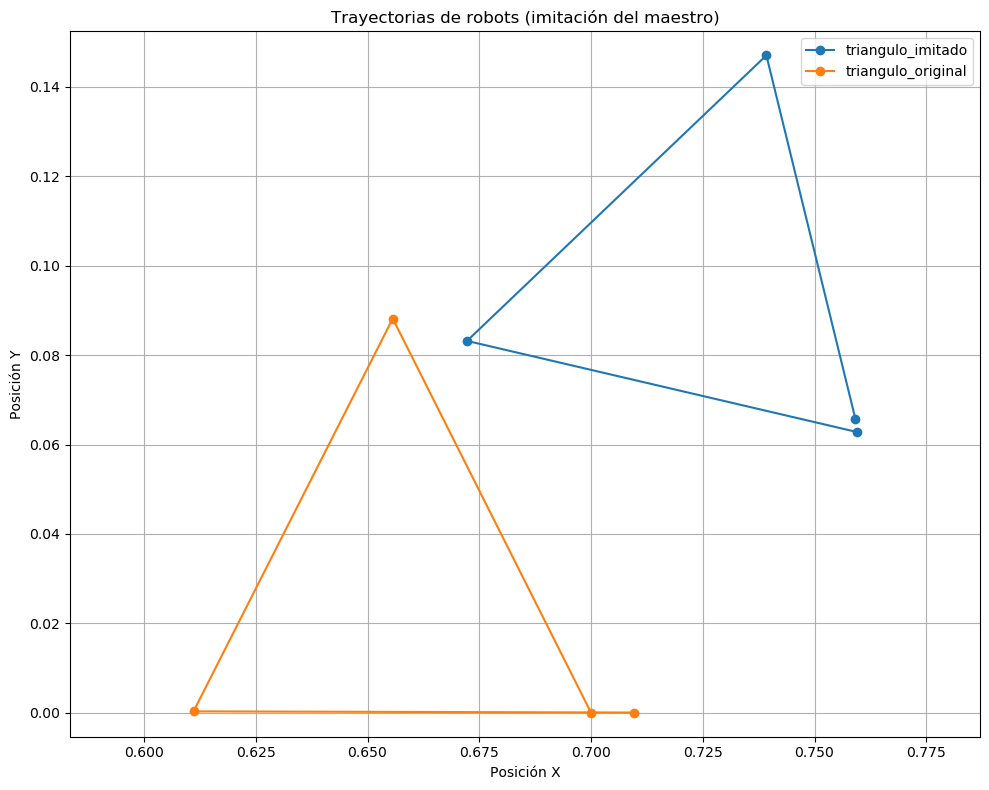

In [4]:

trayectorias = [
    (
        [(0.75913256930872, 0.065762374840884),
         (0.73922725365501, 0.14706082120762),
         (0.67225813762264, 0.083180855019526),
         (0.75944437669295, 0.062803852810531)],
        "triangulo_imitado"
    ),
    (
        [(0.7, 0.0),
         (0.65562939059193, 0.088164064258399),
         (0.61106516380378, 0.00029747635950592),
         (0.70962981900755, 0.00003716567200285)],
        "triangulo_original"
    )
]


ecuaciones = [
    (
        {
            4:  (-0.22, -9.71), 

            5:  (-4.19, 25.95), 

            10: (0.89, -9.74), 
        },
        "Regresión Lineal - Triangulo"
    )
]

#graficar_ecuaciones(ecuaciones)


graficar_trayectorias(trayectorias)


    COMPORTAMIENTO  : CUADRADO  
    ROBOT           : E-PUCK


    NOTA:
        Robot aprendiz estático durante la etapa de observación.
        2 epuck en la arena
          

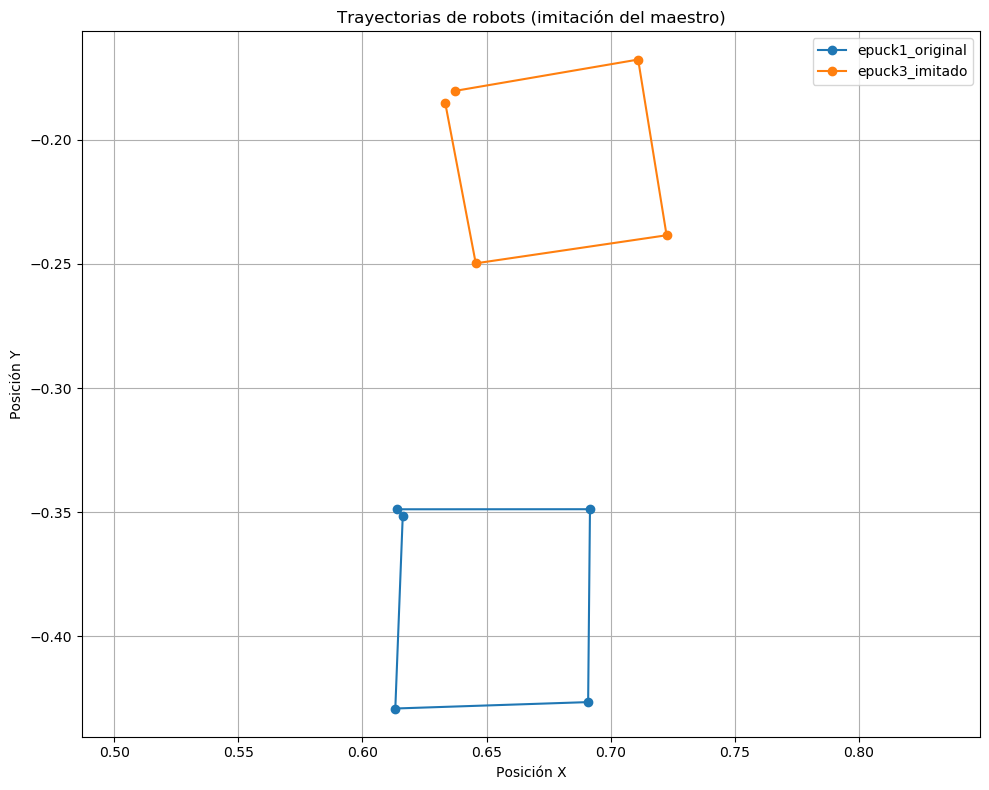

In [3]:

trayectorias = [

    (
        [(0.61393392515043, -0.34881818531851),
         (0.69163392084937, -0.34879233218831),
         (0.69089747211505, -0.42648513457933),
         (0.61322692233698, -0.42906303548526),
         (0.61622304885308, -0.3514418234855)],
        "epuck1_original"
    ),
    (
        [(0.63740999522359, -0.18026837974359),
         (0.71103901475231, -0.16766560558769),
         (0.72249877349669, -0.23844018385177),
         (0.64562974132713, -0.24974795964645),
         (0.63333984926121, -0.18519439927442)],
        "epuck3_imitado"
    )
]

ecuaciones = [
    
    (
        {
            4: (-6.22, 99.36), 
            5: (0.21, 4.61), 
            10: (-0.53, 132.89), 
            11: (0.15, -1.36)
        },
        "Regresión Lineal - Cuadrado Epuck3"
    )
]

#graficar_ecuaciones(ecuaciones)
graficar_trayectorias(trayectorias)

## Step6 

    COMPORTAMIENTO  : TRIANGULO  
    ROBOT           : E-PUCK


    NOTA:
        Robot aprendiz estático durante la etapa de observación.
        6 epuck en la arena
            

    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/E-puck/Argos/step6.argos"   
        LUA_SCRIPT          = "experiments/E-puck/Controller/step6.lua" 

<video width="640" height="480" controls>
  <source src="Robots/E-puck/step6/video_dem/step6.mp4" type="video/mp4">
</video>




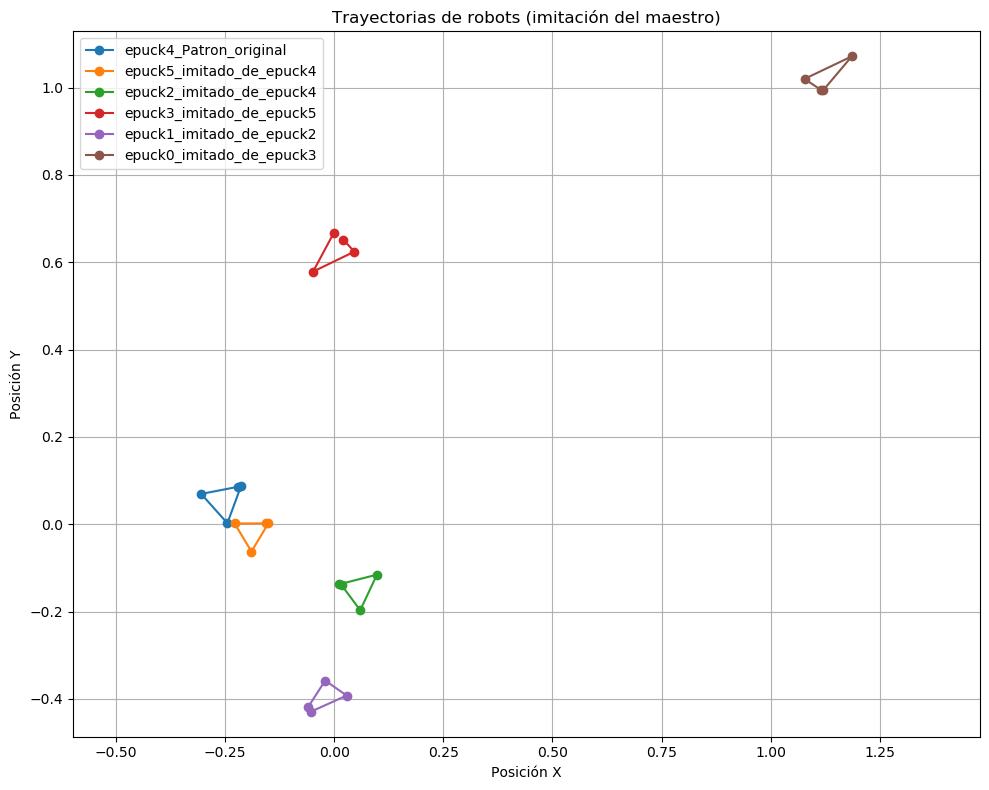

In [9]:

trayectorias = [
    (
        [(-0.2135076996244, 0.086702111473774),
         (-0.24447465419116, 0.002198719104864),
         (-0.3044441171488, 0.069306387143363),
         (-0.21976778418448, 0.085700520741103)],
        "epuck4_Patron_original"
    ),
    (
        [(-0.15084584966946, 0.0016432499830763),
         (-0.18937406716505, -0.062702656079433),
         (-0.22794509576929, 0.0016175967403749),
         (-0.15669661624817, 0.0018337487910196)],
        "epuck5_imitado_de_epuck4"
    ),
    (
        [(0.010873940813613, -0.13783403212594),
         (0.098090410943408, -0.11562901163298),
         (0.059774484068967, -0.1970640492074),
         (0.017213287248517, -0.13992442126854)],
        "epuck2_imitado_de_epuck4"
    ),
    (
        [(0.020995877501682, 0.65166996154052),
         (0.046281885080903, 0.62420138242857),
         (-0.048227239533263, 0.57845471710465),
         (-0.00042201537523012, 0.66770697729356)],
        "epuck3_imitado_de_epuck5"
    ),
    (
        [(-0.053350600254761, -0.42950983037734),
         (0.028670669796331, -0.39246544003009),
         (-0.020524079040577, -0.35811810489815),
         (-0.058999731198589, -0.41808490193448)],
        "epuck1_imitado_de_epuck2"
    ),
    (
        [(1.1147688680796, 0.99482113982987),
         (1.077357803077, 1.0198275096696),
         (1.1856673899107, 1.0714871830146),
         (1.1203762154338, 0.99410263713458)],
        "epuck0_imitado_de_epuck3"
    )
]

graficar_trayectorias(trayectorias)

# Fase 2: Transición de Hardware Simulado y Mejoras (St 2)
Para superar las limitaciones iniciales y acercar la simulación a la plataforma física final (QUPA), se realizaron cambios significativos en el código.

**Actualizaciones Clave:**
* **Optimización de Procesamiento:** Se implementaron mejoras sustanciales en las funciones de procesamiento de datos para la abstracción y reconstrucción de la información observada.
* **Migración a Footbot:** El hardware simulado se cambió de *e-puck* a *footbot*, dado que su morfología y características son más afines a los robots **QUPA** que se utilizarán en la implementación final.
* **Mejora en el Tracking:** A diferencia del *e-puck*, donde se promediaba la señal de varios LEDs, el *footbot* cuenta con un LED direccional. Esto incrementó drásticamente la precisión del rastreo visual por parte del aprendiz.



## St2    
    COMPORTAMIENTO  : TRIANGULO  
    ROBOT           : FOOTBOT


    NOTA:
        Robot aprendiz estático durante la etapa de observación.
        6 footbot en la arena


    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Old versions/Footbot/Argos/St2.argos"   
        LUA_SCRIPT          = "experiments/Old versions/Footbot/Controller/St2.lua" 

<video width="640" height="480" controls>
  <source src="Robots/Footbot/St2/video_dem/St2.mp4" type="video/mp4">
</video>


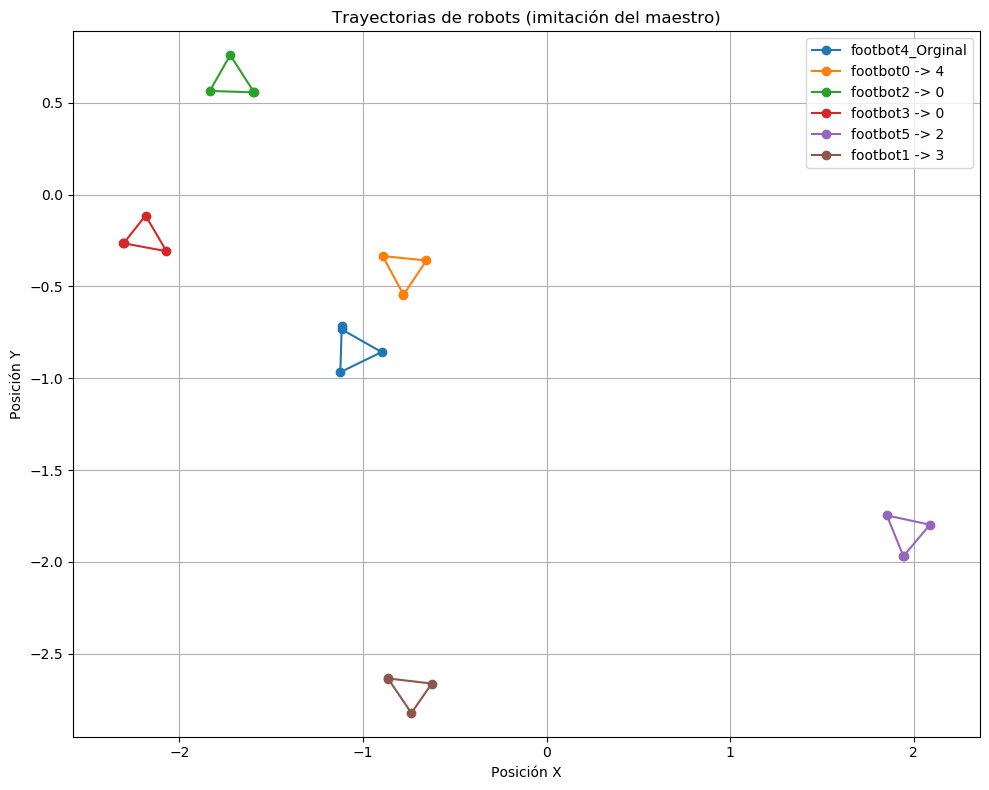

In [3]:
trayectorias = [

    (
        [(-1.115982120085, -0.73376223022345),
         (-0.89862156370101, -0.85727062566884),
         (-1.1233577277108, -0.96678588398107),
         (-1.1157251212059, -0.71710264748482)],

        "footbot4_Orginal"
    ),

    (
        [(-0.77945335139667, -0.54576733717593),
         (-0.6545827545327, -0.35859912906814),
         (-0.89333570316734, -0.33417362174976),
         (-0.77980017398485, -0.54322451253274)],

        "footbot0 -> 4"
    ),

    (
        [(-1.5937441555168, 0.558151575531),
         (-1.7228426039153, 0.76047104199578),
         (-1.8341720076081, 0.56494516657041),
         (-1.5964070529758, 0.55717228598349)],

        "footbot2 -> 0"
    ),

    (
        [(-2.3062882638265, -0.26438654896963),
         (-2.0702806847084, -0.30797552106521),
         (-2.1841934183571, -0.11394332476746),
         (-2.3037972639083, -0.26527818164269)],

        "footbot3 -> 0"
    ),

    (
        [(1.9432238453588, -1.9690419622255),
         (1.852972970946, -1.7466586095274),
         (2.0875110069469, -1.7975652452278),
         (1.9439150560687, -1.9680382246096)],

        "footbot5 -> 2"
    ),

    (
        [(-0.86270445891526, -2.6370358602693),
         (-0.73630240892946, -2.8231732446037),
         (-0.62559273992788, -2.6626490106921),
         (-0.86185096120996, -2.6348165799587)],

        "footbot1 -> 3"
    )

]


graficar_trayectorias(trayectorias)


# Fase 3: Seguimiento Dinámico y Calibración Física (Versiones St4 -> en adelante)
A partir de la migración al *footbot*, las versiones de código *st* introdujeron una mecánica fundamental: el robot aprendiz ya no es estático, sino que **sigue activamente al maestro** para traducir la información sin que este salga de su rango de visión.

**Identificación y Corrección de Errores (ST4 a ST8):**
* **Problema detectado (ST4):** A pesar de la ausencia de ruido ambiental, los comportamientos de movimiento aprendidos e integrados presentaban imperfecciones geométricas. 
* **Diagnóstico:** Se identificó una mala configuración en los parámetros físicos del robot dentro del simulador, específicamente en la longitud o distancia entre ruedas (`FOOTBOT_INTERWHEEL_DISTANCE`). El valor estaba erróneamente configurado en 14.3 (`L = 14.3`), lo que afectaba severamente la cinemática de los giros.
* **Solución (ST8):** Se corrigió el valor a `L = 14` (o `0.14f` en el código fuente). Con esta calibración, el algoritmo funciona de manera óptima, logrando una reconstrucción perfecta de la trayectoria incluso con el aprendiz en movimiento constante.

## St4 

    COMPORTAMIENTO  : TRIANGULO  
    ROBOT           : FOOTBOT


    NOTA:
        6 footbot en la arena
        L = 14.3 cm (Interwheel distance)


    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Old versions/Footbot/Argos/St4.argos"   
        LUA_SCRIPT          = "experiments/Old versions/Footbot/Controller/St4.lua" 


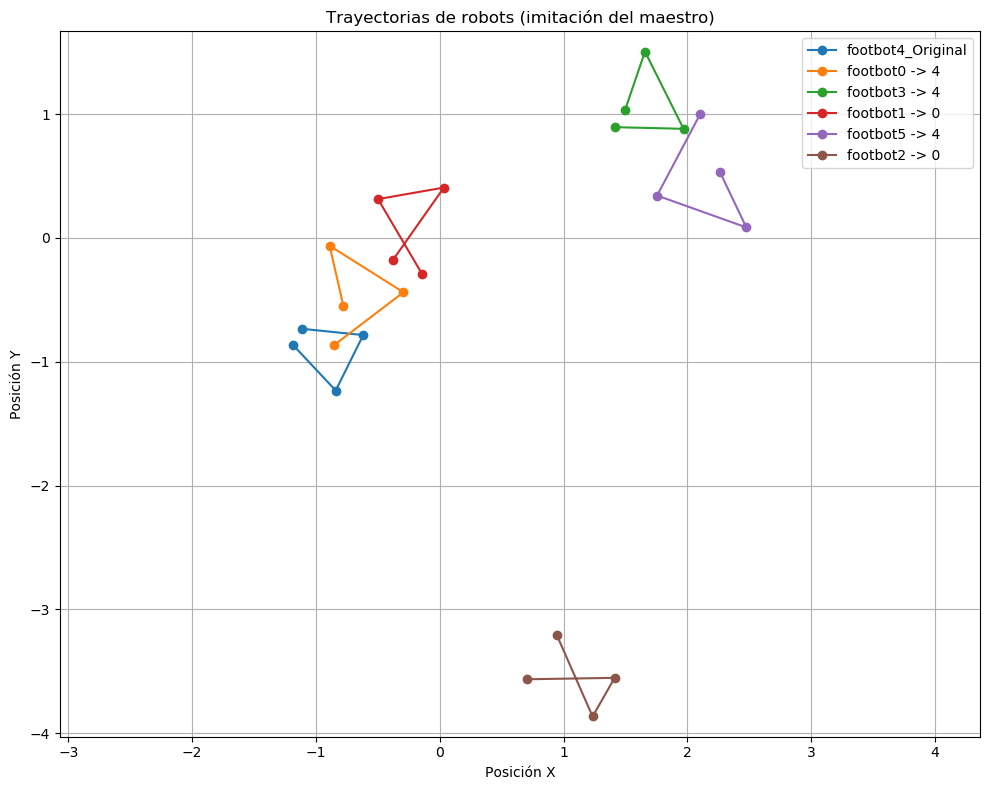

In [13]:
trayectorias = [
    (
        [(-1.115982120085, -0.73376223022345),
         (-0.61858842908281, -0.78472584329113),
         (-0.84050777265038, -1.2327767094394),
         (-1.1817162445084, -0.86881429330004)],
        "footbot4_Original"
    ),
    (
        [(-0.77945335139667, -0.54576733717593),
         (-0.88977871644413, -0.063221859906771),
         (-0.29312786886952, -0.43875907785563),
         (-0.85215081504781, -0.86484259566833)],
        "footbot0 -> 4"
    ),
    (
        [(1.4983570769909, 1.037283824004),
         (1.6579161089034, 1.505859046504),
         (1.9693317160444, 0.88156525676936),
         (1.4167675990884, 0.89509881433616)],
        "footbot3 -> 4"
    ),
    (
        [(-0.14140861251892, -0.29404951707577),
         (-0.49858753578639, 0.31376924929274),
         (0.033288941646927, 0.40706415358477),
         (-0.37964045491152, -0.18017925297385)],
        "footbot1 -> 0"
    ),
    (
        [(2.263906217936, 0.53243058563436),
         (2.4763561699233, 0.08534352285309),
         (1.7559116323358, 0.34259769233105),
         (2.1055401807453, 1.0037321388638)],
        "footbot5 -> 4"
    ),
    (
        [(0.70516233313165, -3.5655531740272),
         (1.4126619427289, -3.5538942241198),
         (1.2349569452299, -3.8661887907074),
         (0.9458661790013, -3.209079945865)],
        "footbot2 -> 0"
    )
]

graficar_trayectorias(trayectorias)

    COMPORTAMIENTO  : TRIANGULO  
    ROBOT           : FOOTBOT

    NOTA:
        6 footbot en la arena
        L = 15 cm (Interwheel distance)


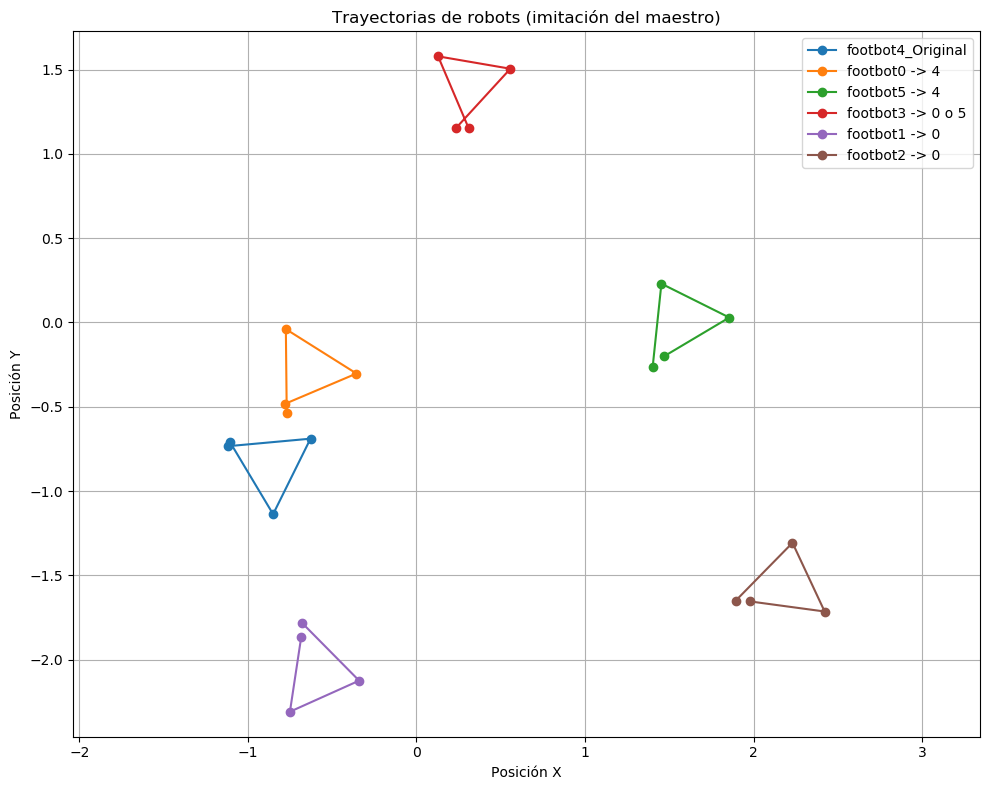

In [6]:
trayectorias = [
    (
        [
            (-1.115982120085, -0.73376223022345), 
            (-0.62873485235281, -0.68933668055626), 
            (-0.85065419592039, -1.1373875467045), 
            (-1.1066622928242, -0.70919166168296)  
        ],
        "footbot4_Original"
    ),
    (
        [
            (-0.76984566142829, -0.53422035148809),
            (-0.77503465360301, -0.03925075831495),
            (-0.35606145605452, -0.30284757836745), 
            (-0.78090776728226, -0.48307866216777)  
        ],
        "footbot0 -> 4"
    ),
    (
        [
            (1.4014518190843, -0.2621303531874),  
            (1.4531787389947, 0.23015630066619), 
            (1.8559181870778, 0.02941253823375),  
            (1.4709180302051, -0.19945429160186)  
        ],
        "footbot5 -> 4"
    ),
    (
        [
            (0.3102083357834, 1.1511262502673), 
            (0.12825311785374, 1.5790448415148),  
            (0.5569817963727, 1.5054653569836),  
            (0.23400932575323, 1.153233468905)  
        ],
        "footbot3 -> 0 o 5"
    ),
    (
        [
            (-0.6778368943438, -1.783605658024), 
            (-0.3403405723795, -2.12491659485),
            (-0.75085132312314, -2.3092479397746),  
            (-0.6839145665872, -1.8663883489159)  
        ],
        "footbot1 -> 0"
    ),
    (
        [
            (1.8946874973885, -1.6497692767414), 
            (2.2308902921132, -1.307179608451), 
            (2.4216318178743, -1.7147514322418), 
            (1.9777776870398, -1.6547626238509)  
        ],
        "footbot2 -> 0"
    )
]

graficar_trayectorias(trayectorias)


    COMPORTAMIENTO  : CADRADO  
    ROBOT           : FOOTBOT

    NOTA:
        6 footbot en la arena
        L = 15 cm (Interwheel distance)

<video width="640" height="480" controls>
  <source src="Robots/Footbot/St4/video_dem/St4.mp4" type="video/mp4">
</video>

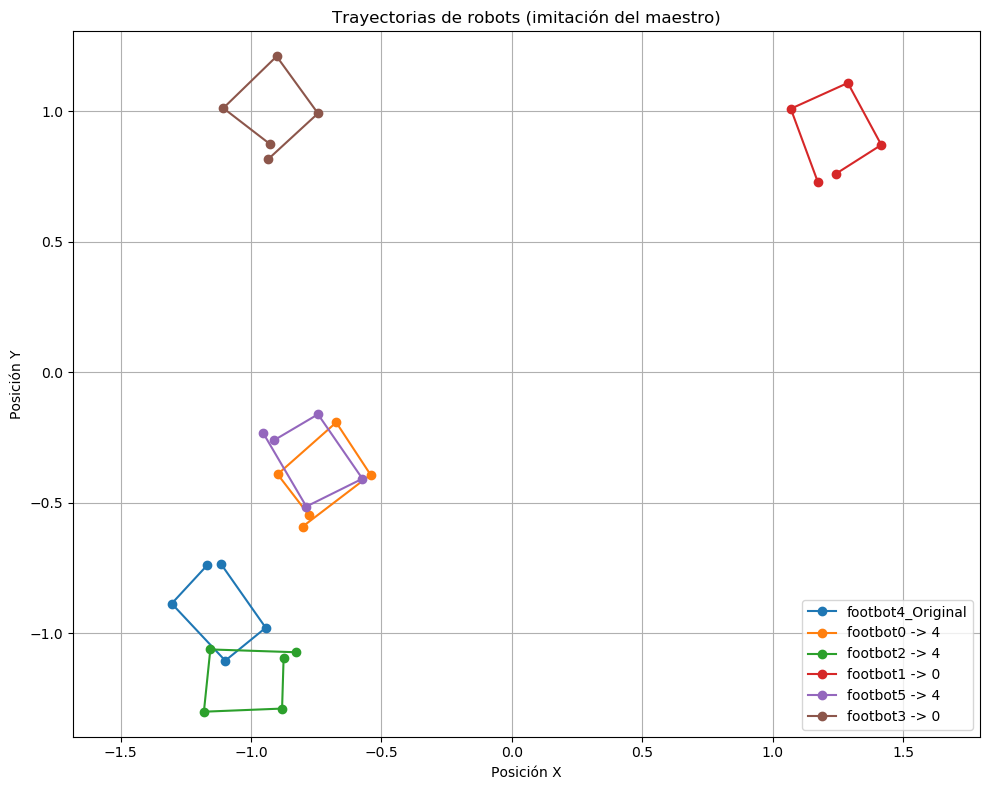

In [ ]:

trayectorias = [
    (
        [
            (-1.115982120085, -0.73376223022345),
            (-0.94367317327257, -0.97933973132438),
            (-1.0988104990465, -1.1055599618611),
            (-1.3040509652172, -0.88675632102171),
            (-1.1690308461385, -0.74071838918434)
        ],
        "footbot4_Original"
    ),
    (
        [
            (-0.77945335139667, -0.54576733717593),
            (-0.89812906393886, -0.39104215605793),
            (-0.67349040535928, -0.19220658183593),
            (-0.54170366840278, -0.39278266463174),
            (-0.80238149318532, -0.59167641916415)
        ],
        "footbot0 -> 4"
    ),
    (
        [
            (-0.87509656835174, -1.094310172098),
            (-0.88097504611577, -1.2892184836668),
            (-1.1807308333305, -1.3012426483322),
            (-1.1560212574067, -1.0625211665065),
            (-0.82830672839388, -1.0732375744508)
        ],
        "footbot2 -> 4"
    ),
    (
        [
            (1.1731637431215, 0.72894848351064),
            (1.0692407775953, 1.0103701062422),
            (1.2879071769435, 1.1092817578482),
            (1.4162716310762, 0.87175096472613),
            (1.2408674524172, 0.76016451676457)
        ],
        "footbot1 -> 0"
    ),
    (
        [
            (-0.91123382606696, -0.26017532121581),
            (-0.74332868091266, -0.16102055002395),
            (-0.57302828023985, -0.40799400211001),
            (-0.7880306315677, -0.51463591671608),
            (-0.95404355298554, -0.23187919469577)
        ],
        "footbot5 -> 4"
    ),
    (
        [
            (-0.92805508223825, 0.87537455375059),
            (-1.1063123224377, 1.0126624427814),
            (-0.9018558459571, 1.211209064159),
            (-0.74337704570417, 0.99261633638335),
            (-0.93336071495935, 0.81785338328509)
        ],
        "footbot3 -> 0"
    )
]

graficar_trayectorias(trayectorias)


## St8

    COMPORTAMIENTO  : CUADRADO  
    ROBOT           : FOOTBOT

    NOTA:
        Segir al maestro para no perderlo de vista si se aleja, o alejarse si se acerca para evitar coliciones.
        6 footbot en la arena
        L = 14 cm (Interwheel distance)

<video width="640" height="480" controls>
  <source src="Robots/Footbot/St8/video_dem/St8.mp4" type="video/mp4">
</video>


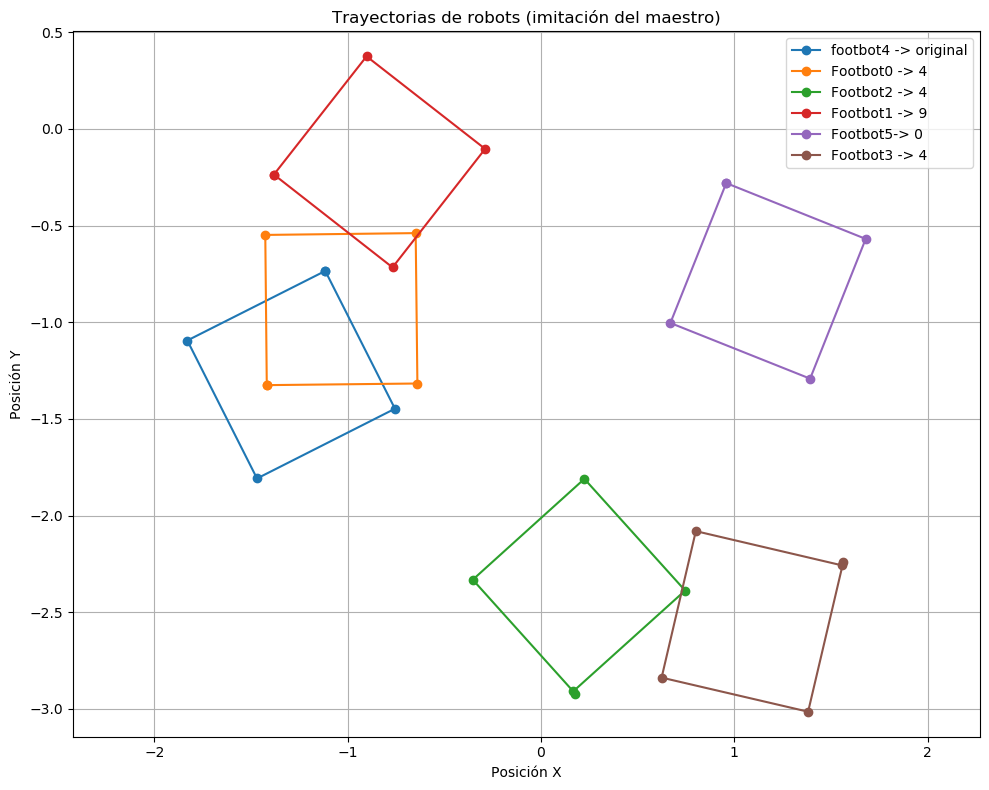

In [4]:
trayectorias = [
    (
        [
            (-1.115982120085, -0.73376223022345),
            (-0.75510329300014, -1.447181125042),
            (-1.4685245360768, -1.8080550053505),
            (-1.828947292311, -1.094405746715),
            (-1.1150703033803, -0.73443425862547)
        ],
        "footbot4 -> original"
    ),
    (
        [
            (-1.4179914510667, -1.3262417475416),
            (-1.4257641848098, -0.54838808448839),
            (-0.64792653919796, -0.53900010042384),
            (-0.63903033545026, -1.3168435260145),
            (-1.4168792300965, -1.3252479458892)
        ],
        "Footbot0 -> 4"
    ),
    (
        [
            (0.17764114820491, -2.9209862257088),
            (-0.35265816405432, -2.3315278721067),
            (0.22456720114388, -1.8100583955815),
            (0.74567162969331, -2.3876133381817),
            (0.16778734055486, -2.9083525104576)
        ],
        "Footbot2 -> 4"
    ),
    (
        [
            (-1.3818017294509, -0.23698454480292),
            (-0.90188585986936, 0.37522252362966),
            (-0.28868212714023, -0.10342214555905),
            (-0.76771439130714, -0.71632313843053),
            (-1.3803123993293, -0.2369034707665)
        ],
        "Footbot1 -> 9"
    ),
    (
        [
            (0.95738885250663, -0.27994556950277),
            (1.6795997273448, -0.56895800657179),
            (1.3920869488463, -1.2917691432982),
            (0.66945773305796, -1.0037994336674),
            (0.9578842587124, -0.28135242766998)
        ],
        "Footbot5-> 0"
    ),
    (
        [
            (1.5631501393269, -2.2424237910567),
            (1.3817323261248, -3.0142826436114),
            (0.62410540096232, -2.8378712509958),
            (0.80099575877613, -2.0803560112228),
            (1.5583990103619, -2.2577252635274)
        ],
        "Footbot3 -> 4"
    )
]

graficar_trayectorias(trayectorias)

# Fase 4: Misión 1 - Resolución de Laberinto
Con el algoritmo base estabilizado, se procedió a un experimento de mayor complejidad orientada a objetivos prácticos.

**Descripción de la Misión:**
* El objetivo fue transferir conocimiento sobre la navegación y escape en un entorno estructurado.
* **Dos maestros**, que ya poseían la solución al laberinto (representada como una trayectoria ininterrumpida), actuaron como guías.
* **Dos aprendices** observaron a estos maestros y lograron aprender y replicar con éxito la trayectoria necesaria para resolver el laberinto de forma autónoma.
  

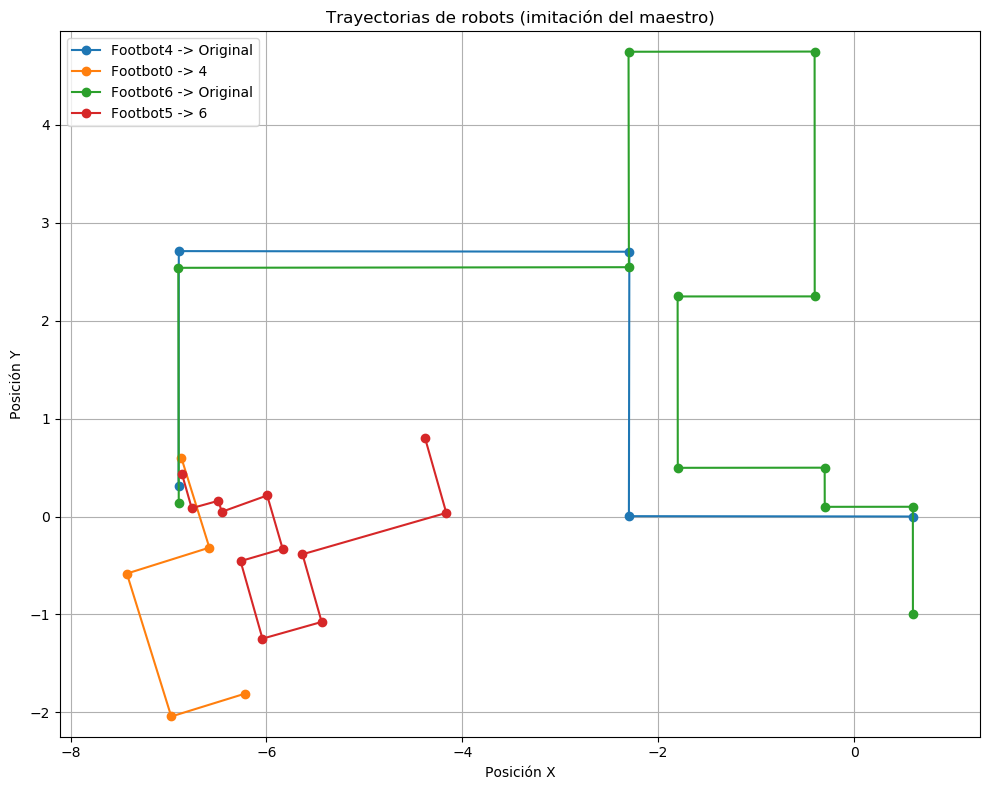

In [6]:
trayectorias = [
    (
        [
            (0.6, 3.885844281541e-34),
            (-2.2994975996051, 0.0036306327419497),
            (-2.294913137451, 2.7031263494131),
            (-6.8944083393148, 2.7094780175982),
            (-6.896461107653, 0.30997927953581)
        ],
        "Footbot4 -> Original"
    ),
    (
        [
            (-6.8680241933823, 0.59874919778927),
            (-6.5824360428712, -0.31773674196198),
            (-7.4247087505585, -0.58245992981832),
            (-6.9714295417524, -2.0415672708545),
            (-6.2140647570406, -1.8068762936384)
        ],
        "Footbot0 -> 4"
    ),
    (
        [
            (0.6, -1.0),
            (0.59934056848307, 0.099499675280555),
            (-0.30015894614013, 0.098897993538211),
            (-0.30094723867604, 0.49839713132524),
            (-1.8004462736295, 0.49703676425295),
            (-1.802088087332, 2.2465356322257),
            (-0.40258853100153, 2.2470713461077),
            (-0.40363309558034, 4.7465707415818),
            (-2.3031318107539, 4.7447045842892),
            (-2.2994957049462, 2.5452079682369),
            (-6.89899090681, 2.5388563000518),
            (-6.8949754584637, 0.13936004375237)
        ],
        "Footbot6 -> Original"
    ),
    (
        [
            (-6.8610689417939, 0.4312414505508),
            (-6.7627302037979, 0.084983115185986),
            (-6.4901604057328, 0.16073267746288),
            (-6.4556541038387, 0.047982847865494),
            (-5.9920825344039, 0.21501498536631),
            (-5.8340205748906, -0.33028389482699),
            (-6.2641570137867, -0.45515990130489),
            (-6.0402571313042, -1.2470081089795),
            (-5.4360166680387, -1.0762871307634),
            (-5.6319494858706, -0.38564762339209),
            (-4.1636979067894, 0.037074004072368),
            (-4.3803222663001, 0.79980276239664)
        ],
        "Footbot5 -> 6"
    )
]

graficar_trayectorias(trayectorias)

# Fase 5: Escalabilidad a Enjambre y Trayectorias Complejas (Versión St10)
Expansión del sistema para validar su rendimiento en escenarios de robótica de enjambres a gran escala.

**Características del Experimento:**
* **Tamaño del Enjambre:** Incremento a un grupo de **21 a 31 robots** simultáneos.
* **Complejidad de Trayectorias:** Se introdujo el aprendizaje de patrones geométricos avanzados, incluyendo figuras con diferente cantidad de segmentos, ángulos variados e incluso trayectorias abiertas.
* **Resultado:** El algoritmo demostró ser altamente escalable, permitiendo la transmisión social de comportamientos de movimiento complejos en formaciones densas.


# St10

    COMPORTAMIENTO  : CUADRADO  
    ROBOT           : FOOTBOT


    NOTA:
        Segir al maestro para no perderlo de vista si se aleja, o alejarse si se acerca para evitar coliciones.
        Mejoras en las funciones de gaurdar datos observados con el objetivo de evitar confundir datos
        21 footbot en la arena

        
    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments//Footbot/Argos/St.argos"   
        LUA_SCRIPT          = "experiments/Footbot/Controller/St10.lua" 
            

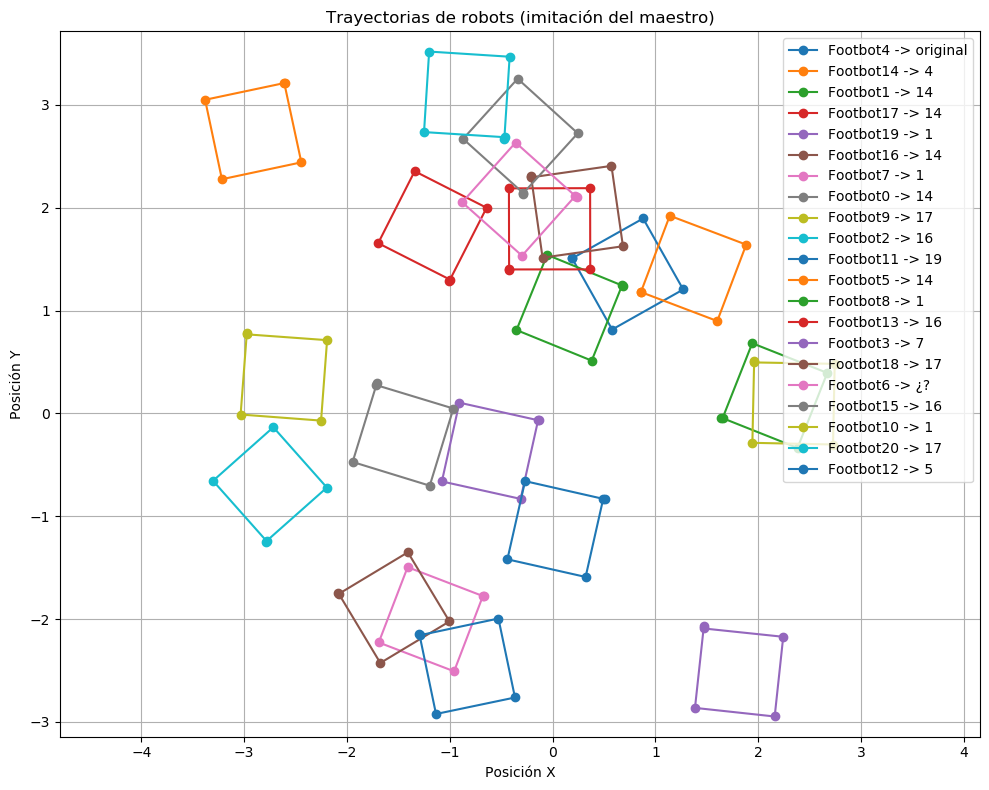

In [4]:
trayectorias = [
    (
        [
            (0.18850595996279, 1.5066989025753),
            (0.87976712068233, 1.8950756769771),
            (1.2695439633791, 1.2046009961918),
            (0.57882298890078, 0.81526077565978),
            (0.18991954616251, 1.5062277677329)
        ],
        "Footbot4 -> original"
    ),
    (
        [
            (0.85793520685859, 1.1786014743897),
            (1.1389763629705, 1.9217341075819),
            (1.8821080336546, 1.6406908425852),
            (1.6005949888205, 0.89773700662901),
            (0.85781928456918, 1.1797197187725)
        ],
        "Footbot14 -> 4"
    ),
    (
        [
            (0.67521303493688, 1.2446874092144),
            (0.37968305474751, 0.51258452068796),
            (-0.35162725992225, 0.81006598841927),
            (-0.053683489547655, 1.5411880778687),
            (0.68187796010209, 1.2408893090352)
        ],
        "Footbot1 -> 14"
    ),
    (
        [
            (-0.42336987935643, 1.398414674761),
            (-0.42517170674526, 2.1879126135886),
            (0.36432607687924, 2.1897152888047),
            (0.36562960131431, 1.4002165232515),
            (-0.42886983023094, 1.3994102677202)
        ],
        "Footbot17 -> 14"
    ),
    (
        [
            (-0.14131388615314, -0.065876841869525),
            (-0.3112330274624, -0.83175393870857),
            (-1.0771108440876, -0.66183874456881),
            (-0.90671146692617, 0.10393149216092),
            (-0.13129064740655, -0.069136556390148)
        ],
        "Footbot19 -> 1"
    ),
    (
        [
            (-0.2096160677465, 2.2947929304861),
            (0.57193999061374, 2.4065085052071),
            (0.68365638329517, 1.6249527185915),
            (-0.097969878454066, 1.5137304774259),
            (-0.21009407202138, 2.3053289607357)
        ],
        "Footbot16 -> 14"
    ),
    (
        [
            (-0.67793925802363, -1.7754888222265),
            (-0.95832347367178, -2.5081722010892),
            (-1.6910081433208, -2.2277917844057),
            (-1.4101645516649, -1.4952845283161),
            (-0.66850233537376, -1.7801830255038)
        ],
        "Footbot7 -> 1"
    ),
    (
        [
            (-0.28446766728887, 2.1404197724854),
            (-0.87074903911981, 2.6691794169589),
            (-0.34042825847532, 3.2540468118464),
            (0.24410373062227, 2.723356361859),
            (-0.29032182045523, 2.1354623857633)
        ],
        "Footbot0 -> 14"
    ),
    (
        [
            (-2.9756974919093, 0.76849694361347),
            (-2.1932370291906, 0.71194390448245),
            (-2.251887401661, -0.070360471708338),
            (-3.0341545405102, -0.011215508485261),
            (-2.9737483408953, 0.78098464792841)
        ],
        "Footbot9 -> 17"
    ),
    (
        [
            (-0.46776878315052, 2.6854177040144),
            (-1.2506898425523, 2.7351656365447),
            (-1.2009459209754, 3.5180867982615),
            (-0.41805636572754, 3.4678478941935),
            (-0.46976996351078, 2.6700222883336)
        ],
        "Footbot2 -> 16"
    ),
    (
        [
            (0.49185544671717, -0.83022674970894),
            (0.32042003462321, -1.5906412035282),
            (-0.43999584870721, -1.419212819679),
            (-0.26808673537406, -0.65890547184951),
            (0.50673819401032, -0.83462207771873)
        ],
        "Footbot11 -> 19"
    ),
    (
        [
            (-2.6098355295742, 3.2126500587508),
            (-2.4436916638294, 2.4408283018309),
            (-3.2159523097093, 2.2767444976004),
            (-3.3795478286916, 3.0491087291352),
            (-2.6021875255703, 3.2132457325966)
        ],
        "Footbot5 -> 14"
    ),
    (
        [
            (1.6521438464963, -0.047443396887854),
            (1.9408478701376, 0.68200175442873),
            (2.6702943553903, 0.3933015148199),
            (2.3811329897744, -0.33596229741362),
            (1.638115361681, -0.040793196889572)
        ],
        "Footbot8 -> 1"
    ),
    (
        [
            (-0.99699738292253, 1.2999957457854),
            (-1.6965971006521, 1.6549612046664),
            (-1.3416352861296, 2.3545626007691),
            (-0.64225845015958, 1.9991585426791),
            (-1.0049171934246, 1.2866428379433)
        ],
        "Footbot13 -> 16"
    ),
    (
        [
            (1.4668449264006, -2.0913926762925),
            (2.2421139223328, -2.1725136925111),
            (2.1589048110055, -2.9475596590208),
            (1.3839116073518, -2.8638605508968),
            (1.4702736934877, -2.0690388201675)
        ],
        "Footbot3 -> 7"
    ),
    (
        [
            (-2.0800169474117, -1.7554659251194),
            (-1.4078890742427, -1.3508866817623),
            (-1.0033064743253, -2.023012356798),
            (-1.675687807478, -2.4271699325358),
            (-2.0845610204039, -1.7459558013514)
        ],
        "Footbot18 -> 17"
    ),
    (
        [
            (0.22101902573209, 2.114657060777),
            (-0.29797851155346, 1.5330542767494),
            (-0.87958595698189, 2.052046363233),
            (-0.36022625996065, 2.6333255659581),
            (0.23562151932002, 2.1002538845796)
        ],
        "Footbot6 -> ¿?"
    ),
    (
        [
            (-1.7157083834027, 0.27499244871934),
            (-0.96507536252164, 0.046973392682519),
            (-1.1951054464363, -0.70304404957623),
            (-1.9449773050561, -0.47253982217851),
            (-1.7095733486856, 0.29151840262282)
        ],
        "Footbot15 -> 16"
    ),
    (
        [
            (1.9580782832732, 0.49536633812425),
            (2.7424573042963, 0.48150367851831),
            (2.726491923763, -0.30283369138229),
            (1.9421648045403, -0.28637242623546),
            (1.9593445629838, 0.50794165060918)
        ],
        "Footbot10 -> 1"
    ),
    (
        [
            (-2.7813155146924, -1.2422687112515),
            (-3.302454081481, -0.65587734343378),
            (-2.7160654908551, -0.13473588089015),
            (-2.1952948695628, -0.72145383970599),
            (-2.7898293234425, -1.2484820931459)
        ],
        "Footbot20 -> 17"
    ),
    (
        [
            (-1.2945667566708, -2.15799437831),
            (-0.52717903763456, -1.9950259438656),
            (-0.36626878470182, -2.7628461661176),
            (-1.134190587056, -2.923270941845),
            (-1.2961622337183, -2.1454565793833)
        ],
        "Footbot12 -> 5"
    )
]
graficar_trayectorias(trayectorias)

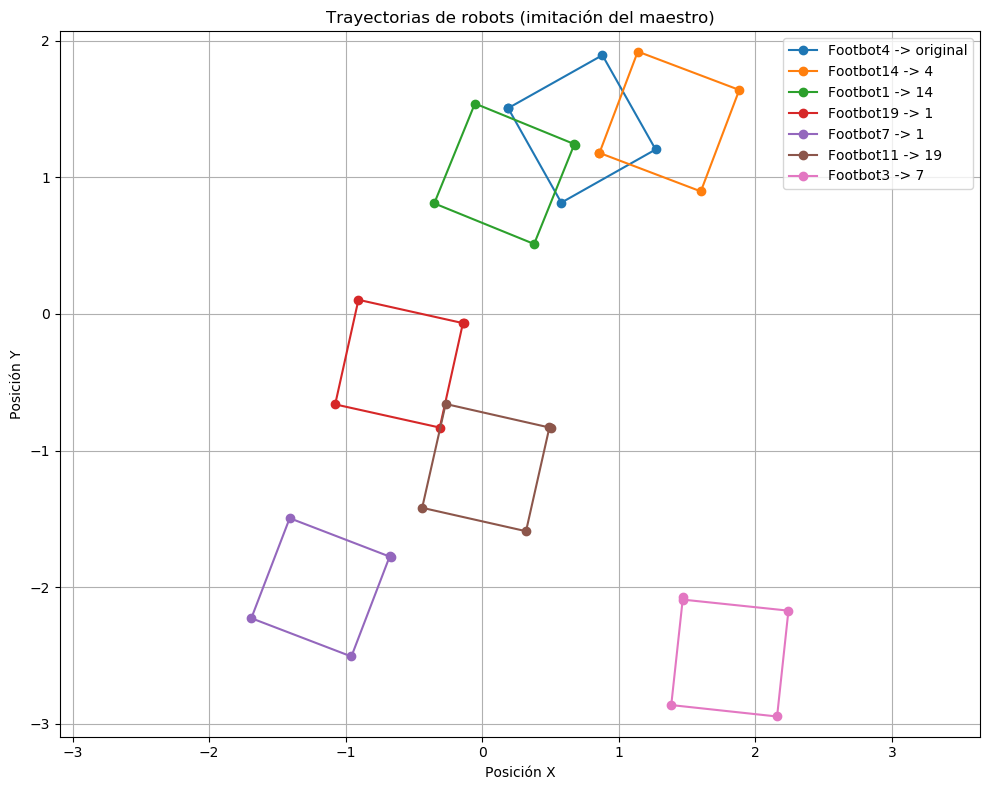

In [7]:
trayectorias = [
    (
        [
            (0.18850595996279, 1.5066989025753),
            (0.87976712068233, 1.8950756769771),
            (1.2695439633791, 1.2046009961918),
            (0.57882298890078, 0.81526077565978),
            (0.18991954616251, 1.5062277677329)
        ],
        "Footbot4 -> original"
    ),
    (
        [
            (0.85793520685859, 1.1786014743897),
            (1.1389763629705, 1.9217341075819),
            (1.8821080336546, 1.6406908425852),
            (1.6005949888205, 0.89773700662901),
            (0.85781928456918, 1.1797197187725)
        ],
        "Footbot14 -> 4"
    ),
    (
        [
            (0.67521303493688, 1.2446874092144),
            (0.37968305474751, 0.51258452068796),
            (-0.35162725992225, 0.81006598841927),
            (-0.053683489547655, 1.5411880778687),
            (0.68187796010209, 1.2408893090352)
        ],
        "Footbot1 -> 14"
    ),
    (
        [
            (-0.14131388615314, -0.065876841869525),
            (-0.3112330274624, -0.83175393870857),
            (-1.0771108440876, -0.66183874456881),
            (-0.90671146692617, 0.10393149216092),
            (-0.13129064740655, -0.069136556390148)
        ],
        "Footbot19 -> 1"
    ),
    (
        [
            (-0.67793925802363, -1.7754888222265),
            (-0.95832347367178, -2.5081722010892),
            (-1.6910081433208, -2.2277917844057),
            (-1.4101645516649, -1.4952845283161),
            (-0.66850233537376, -1.7801830255038)
        ],
        "Footbot7 -> 1"
    ),
    (
        [
            (0.49185544671717, -0.83022674970894),
            (0.32042003462321, -1.5906412035282),
            (-0.43999584870721, -1.419212819679),
            (-0.26808673537406, -0.65890547184951),
            (0.50673819401032, -0.83462207771873)
        ],
        "Footbot11 -> 19"
    ),
    (
        [
            (1.4668449264006, -2.0913926762925),
            (2.2421139223328, -2.1725136925111),
            (2.1589048110055, -2.9475596590208),
            (1.3839116073518, -2.8638605508968),
            (1.4702736934877, -2.0690388201675)
        ],
        "Footbot3 -> 7"
    ),
]
graficar_trayectorias(trayectorias)

    COMPORTAMIENTO  : TRAYECTORIA DE 5 SEGMENTOS  
    ROBOT           : FOOTBOT

    NOTA:
        Pruebas con angulos amplios y finos: angulos: 10°, 135°.
        31 footbot en la arena.

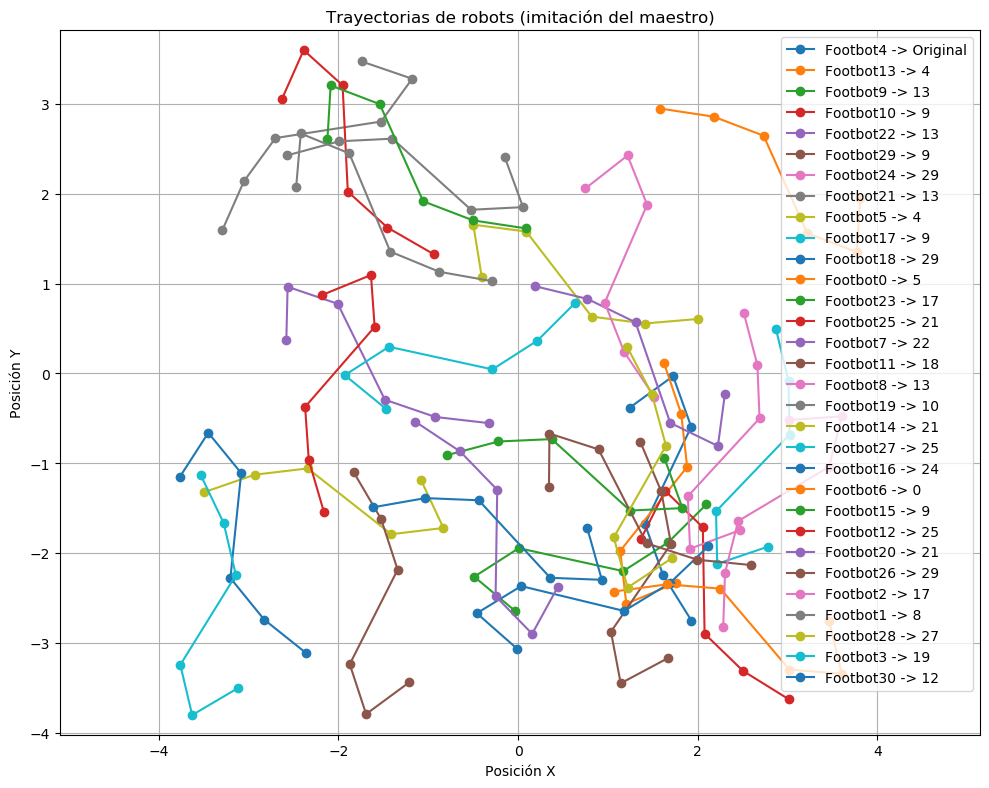

In [7]:
trayectorias = [
    (
        [
            (1.240480613053, -0.38373682088704),
            (1.7253760685333, -0.031208104897654),
            (1.9269965927944, -0.59563721330588),
            (1.4124985810144, -1.6795836708146),
            (1.6134328382902, -2.2447823741524),
            (1.930242068098, -2.7543096612317)
        ],
        "Footbot4 -> Original"
    ),
    (
        [
            (1.7522868630645, -2.3356751112469),
            (1.2044265797026, -2.5664983204335),
            (1.137284017318, -1.9759439529237),
            (1.8820993873637, -1.0416394364751),
            (1.8157435913828, -0.45049846391011),
            (1.6233175011473, 0.11779589977986)
        ],
        "Footbot13 -> 4"
    ),
    (
        [
            (-0.032935432116369, -2.6464407749956),
            (-0.48851255379383, -2.2644949459342),
            (0.0077519510093941, -1.9465995591354),
            (1.1698257176155, -2.2022084234445),
            (1.671180696848, -1.8820616978573),
            (2.0964544997217, -1.4588259756001)
        ],
        "Footbot9 -> 13"
    ),
    (
        [
            (1.3698806812203, -1.8393027036836),
            (1.636387295286, -1.3078825734732),
            (2.0566293712481, -1.7139170719315),
            (2.0760031225904, -2.8986121609489),
            (2.5032033798105, -3.3125574246449),
            (3.0131535125074, -3.6286857944055)
        ],
        "Footbot10 -> 9"
    ),
    (
        [
            (-2.5809572455497, 0.36947597125444),
            (-2.5664630551543, 0.96380168042265),
            (-2.0084825041387, 0.77408178066528),
            (-1.4836489510494, -0.29376702515849),
            (-0.92073404682902, -0.48606250537545),
            (-0.32467245682692, -0.55459618271199)
        ],
        "Footbot22 -> 13"
    ),
    (
        [
            (1.6666469410344, -3.1717363491505),
            (1.1419992329842, -3.4513394832011),
            (1.0337699575968, -2.8770975130384),
            (1.7027408792999, -1.8991631072121),
            (1.593406182203, -1.3144438026599),
            (1.3600055013661, -0.76171384491386)
        ],
        "Footbot29 -> 9"
    ),
    (
        [
            (2.4665692038429, -1.7473441956541),
            (1.9141363138101, -1.9530822476662),
            (1.8893650705078, -1.3692622032549),
            (2.688257302875, -0.50103097663342),
            (2.6638919000857, 0.093323352241418),
            (2.513421114158, 0.66897076255063)
        ],
        "Footbot24 -> 29"
    ),
    (
        [
            (-1.7416798350421, 3.4722878044436),
            (-1.1791772765612, 3.27987908404),
            (-1.5261072253375, 2.803459577389),
            (-2.7016670495415, 2.6195834498877),
            (-3.0525222830245, 2.1392176036382),
            (-3.2950519704354, 1.5904320036729)
        ],
        "Footbot21 -> 13"
    ),
    (
        [
            (-0.40424792903631, 1.0682335434955),
            (-0.49922327376609, 1.6551004909605),
            (0.090224641642118, 1.5788526077795),
            (0.8189564967137, 0.63194989455252),
            (1.4087855164592, 0.55479765173687),
            (2.0066263745417, 0.60551838134678)
        ],
        "Footbot5 -> 4"
    ),
    (
        [
            (2.779757702859, -1.9309715518303),
            (2.2165301316814, -2.121255111811),
            (2.203414685769, -1.5370501807929),
            (3.0229372679098, -0.68132795159467),
            (3.0104401586889, -0.086605694262326),
            (2.8703207925286, 0.496791980769)
        ],
        "Footbot17 -> 9"
    ),
    (
        [
            (-0.01384583741307, -3.0641257937325),
            (-0.46015905625611, -2.6713984650799),
            (0.033943639685961, -2.3688899149827),
            (1.1808508221962, -2.6457620452593),
            (1.6886216899467, -2.3358919321967),
            (2.1188121361561, -1.9248595996442)
        ],
        "Footbot18 -> 29"
    ),
    (
        [
            (3.8085088148565, 1.9484889883892),
            (3.7704218444683, 1.3502000727135),
            (3.2195572354802, 1.5596854379294),
            (2.7331143943123, 2.6455605195219),
            (2.1774103584822, 2.8577956854757),
            (1.5841699203867, 2.9475289937477)
        ],
        "Footbot0 -> 5"
    ),
    (
        [
            (1.6279672563791, -0.94146615307132),
            (1.8296610263343, -1.5007065907598),
            (1.2459357105142, -1.5277652680756),
            (0.37458415980563, -0.73227753284964),
            (-0.2196702465895, -0.75896913425056),
            (-0.79472428376348, -0.91169193131531)
        ],
        "Footbot23 -> 17"
    ),
    (
        [
            (-2.6290507208168, 3.0553373147798),
            (-2.3878206583666, 3.598698324702),
            (-1.9545185712707, 3.2066412369338),
            (-1.8963736336415, 2.0232152939996),
            (-1.4558516348144, 1.623476492212),
            (-0.93582619385073, 1.3242110168302)
        ],
        "Footbot25 -> 21"
    ),
    (
        [
            (2.3031237887341, -0.22505092843534),
            (2.22431292931, -0.80926150001337),
            (1.6940951761978, -0.55197363731388),
            (1.307025685884, 0.56787233684985),
            (0.77222303171511, 0.82832744276871),
            (0.18921805851968, 0.97007187911266)
        ],
        "Footbot7 -> 22"
    )
]

#graficar_trayectorias(trayectorias) 

trayectorias += [
    (
        [
            (0.34368674133569, -1.2648483829195),
            (0.34863358718131, -0.6703665422804),
            (0.89531578630624, -0.84648851947434),
            (1.430404707408, -1.8924142214087),
            (1.996335464108, -2.0756439125784),
            (2.5884449912674, -2.134105064299)
        ],
        "Footbot11 -> 18"
    ),
    (
        [
            (0.75016048290906, 2.059289494263),
            (1.2184027005137, 2.4255946534369),
            (1.4360888339823, 1.8779115842606),
            (0.96407746387067, 0.78568605945695),
            (1.1811580142867, 0.23723073641654),
            (1.5157614391881, -0.2607921868002)
        ],
        "Footbot8 -> 13"
    ),
    (
        [
            (-0.14779691166891, 2.4041413825956),
            (0.054660738459255, 1.8504978655737),
            (-0.52394491594165, 1.8210972922073),
            (-1.3988198176862, 2.6127084139807),
            (-1.9929498568484, 2.583378605418),
            (-2.5721466264687, 2.4267983190912)
        ],
        "Footbot19 -> 10"
    ),
    (
        [
            (-1.0835529205157, -1.1830487229426),
            (-0.83178059044479, -1.7216058916297),
            (-1.4119475722078, -1.7913606909134),
            (-2.3431740428614, -1.0587659485515),
            (-2.9338752111914, -1.1289291215057),
            (-3.50091796692, -1.325012769934)
        ],
        "Footbot14 -> 21"
    ),
    (
        [
            (-1.473526308289, -0.39354146363961),
            (-1.9298744522253, -0.020370436412767),
            (-1.4383022056856, 0.29556655917804),
            (-0.28561393570075, 0.043844462299928),
            (0.21525836054641, 0.36474582402569),
            (0.63635629085296, 0.78508845986574)
        ],
        "Footbot27 -> 25"
    ),
    (
        [
            (-3.7691675873506, -1.1572351872631),
            (-3.4497180028924, -0.66179376083081),
            (-3.0836289186432, -1.1108146844948),
            (-3.2035322955233, -2.2795336017992),
            (-2.8283075941427, -2.7411147588878),
            (-2.363249940806, -3.1122384276104)
        ],
        "Footbot16 -> 24"
    ),
    (
        [
            (3.4635129854356, -2.7616560393392),
            (3.6033372553373, -3.3446220910779),
            (3.0208006759079, -3.2986809071814),
            (2.2522000965955, -2.3969431705511),
            (1.6592554182139, -2.3493264772149),
            (1.0646912490404, -2.4298232643565)
        ],
        "Footbot6 -> 0"
    ),
    (
        [
            (-2.1230621253368, 2.611850888907),
            (-2.0870121609624, 3.2052592897594),
            (-1.540953970951, 2.9972019191407),
            (-1.0572531030416, 1.9155775543239),
            (-0.50168640494255, 1.7029831398423),
            (0.091495891690857, 1.612866288112)
        ],
        "Footbot15 -> 9"
    ),
    (
        [
            (-2.1886971841571, 0.86948336287803),
            (-1.6384412813572, 1.0945424030596),
            (-1.5975698713949, 0.51664056421307),
            (-2.3716680911684, -0.37376732431938),
            (-2.3305568026547, -0.96719853605512),
            (-2.1625163509919, -1.5431748294995)
        ],
        "Footbot12 -> 25"
    ),
    (
        [
            (0.44139339638246, -2.3789286284985),
            (0.15630326700699, -2.9006123086317),
            (-0.25083886702681, -2.4814432508023),
            (-0.23259873602414, -1.2967301657882),
            (-0.64644444478471, -0.86943346506862),
            (-1.1461031969764, -0.53727775555371)
        ],
        "Footbot20 -> 21"
    ),
    (
        [
            (-1.213890131163, -3.441442535148),
            (-1.6925907033549, -3.7939746504464),
            (-1.8748049808601, -3.2387653063031),
            (-1.3413917871518, -2.186375346927),
            (-1.5260730589132, -1.6209166225573),
            (-1.8295867892042, -1.1033591865853)
        ],
        "Footbot26 -> 29"
    ),
    (
        [
            (3.0113528933311, -0.52079816731952),
            (3.6043596052506, -0.47865353833527),
            (3.462885336371, -1.0404595891565),
            (2.4496211144875, -1.6449013799588),
            (2.303529583203, -2.2215364513794),
            (2.2834771088221, -2.8211898364916)
        ],
        "Footbot2 -> 17"
    ),
    (
        [
            (-2.4710744657473, 2.0780845637095),
            (-2.4201106002492, 2.6703985130193),
            (-1.8794581828246, 2.4486726014077),
            (-1.4231151667413, 1.3552244554698),
            (-0.87769587300535, 1.1306248099651),
            (-0.28696783741408, 1.0256168484977)
        ],
        "Footbot1 -> 8"
    ),
    (
        [
            (1.7099208923339, -2.0595309552616),
            (1.2188562447785, -2.3856730338528),
            (1.0651147431581, -1.8270993518967),
            (1.6464798687962, -0.80617069712002),
            (1.4894486757045, -0.23241818470591),
            (1.2137190147738, 0.29482421921892)
        ],
        "Footbot28 -> 27"
    ),
    (
        [
            (-3.121097992011, -3.5060166810669),
            (-3.6292784599815, -3.8047855817394),
            (-3.7611619391681, -3.2457801026892),
            (-3.1425176170836, -2.2470008827383),
            (-3.2782687399073, -1.6678442771838),
            (-3.5343538360918, -1.1307857869562)
        ],
        "Footbot3 -> 19"
    ),
    (
        [
            (0.77054306119243, -1.7269211641717),
            (0.93196527176442, -2.2990864496608),
            (0.35805917880893, -2.2766286513208),
            (-0.4388360777367, -1.4133565751204),
            (-1.0332004318638, -1.3892369638366),
            (-1.6191899999974, -1.4923273341521)
        ],
        "Footbot30 -> 12"
    )
]

graficar_trayectorias(trayectorias) 

    COMPORTAMIENTO  : TRAYECTORIA DE 10 SEGMENTOS  
    ROBOT           : FOOTBOT

    NOTA:
        31 footbot en la arena.

<video width="640" height="480" controls>
  <source src="Robots/Footbot/St10/video_dem/St10.mp4" type="video/mp4">
</video>


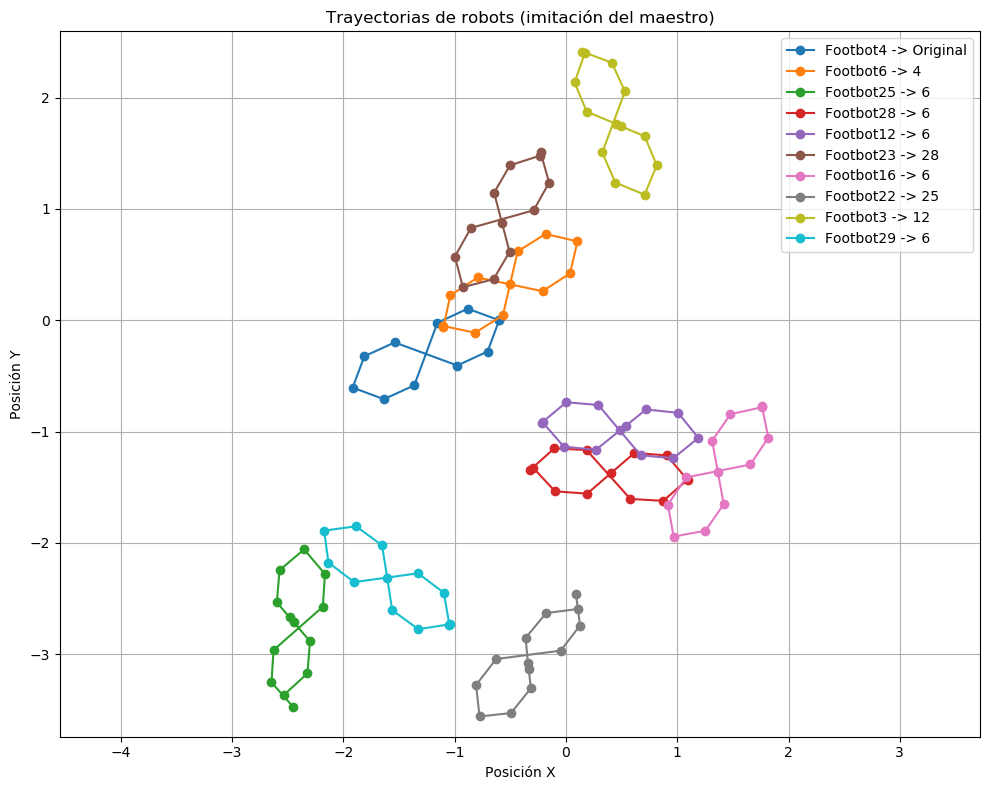

In [3]:
trayectorias = [
    (
        [
            (-0.6, 0.0),
            (-0.70386638322003, -0.28091283336882),
            (-0.97611246616893, -0.40658840967722),
            (-1.5388704122551, -0.1989158266428),
            (-1.8114193798829, -0.32393318706313),
            (-1.9157399807187, -0.6050550332486),
            (-1.6350005340222, -0.70939039308291),
            (-1.3624515647223, -0.584373036308),
            (-1.1540993696732, -0.021866351507283),
            (-0.88185328504342, 0.10380922115976),
            (-0.60048018244128, 0.00016821916974499)
        ],
        "Footbot4 -> Original"
    ),
    (
        [
            (-1.1005209566082, -0.064646368083357),
            (-1.0392824276324, 0.22341627815794),
            (-0.79219474838754, 0.38430886179397),
            (-0.21026485743462, 0.26098621916486),
            (0.037217445501986, 0.42127113560088),
            (0.10389336919814, 0.70849346832997),
            (-0.18294416804144, 0.77523724369222),
            (-0.43318613780616, 0.61929590449068),
            (-0.50099150947268, 0.32720908223635),
            (-0.56622732062848, 0.044641764694428),
            (-0.81608533206769, -0.11191403629466),
            (-1.1045756306936, -0.050957536905267)
        ],
        "Footbot6 -> 4"
    ),
    (
        [
            (-2.4543195855997, -3.4705997089182),
            (-2.6454212995047, -3.2531361933359),
            (-2.6271281749438, -2.9638602509561),
            (-2.1842991743906, -2.5742067985387),
            (-2.1649611974444, -2.2799878539561),
            (-2.3522063645431, -2.0587233109439),
            (-2.5732954065493, -2.2456193780511),
            (-2.597356444093, -2.5344727590564),
            (-2.445700709137, -2.7137960906825),
            (-2.4830646523231, -2.668134902113),
            (-2.2993253687346, -2.8846895485654),
            (-2.3226642723259, -3.1736021734627),
            (-2.5367886178406, -3.3689812746174)
        ],
        "Footbot25 -> 6"
    ),
    (
        [
            (-0.31954233753107, -1.3433002982925),
            (-0.10371903153726, -1.1503481118403),
            (0.18570260746273, -1.1661697465377),
            (0.5791242271186, -1.6056544059959),
            (0.87349761251422, -1.6224786347874),
            (1.093154747605, -1.4333503883514),
            (0.9043770874507, -1.2138657660607),
            (0.61532872833838, -1.1922728195179),
            (0.40702719132994, -1.3715911748321),
            (0.19128148131243, -1.5578135918743),
            (-0.097819951493262, -1.5369432589676),
            (-0.2950208479637, -1.3244955361243)
        ],
        "Footbot28 -> 6"
    ),
    (
        [
            (-0.21875638440406, -0.92256821469202),
            (0.0030825003854505, -0.73656349738041),
            (0.29185613601018, -0.76156342966071),
            (0.67113024952634, -1.2133138956574),
            (0.96482131421288, -1.2394730857633),
            (1.1903707242442, -1.0574120678853),
            (1.0086546404353, -0.8320462113751),
            (0.72043727858772, -0.80128972302581),
            (0.53764352949349, -0.94874400238933),
            (0.4903611015555, -0.98568127706891),
            (0.26880246345142, -1.1649484587793),
            (-0.019490881171333, -1.134912535418),
            (-0.20984930913262, -0.91631267856954)
        ],
        "Footbot12 -> 6"
    ),
    (
        [
            (-0.2279337573835, 1.5105234010797),
            (-0.15096763226146, 1.236632069843),
            (-0.29006427957526, 0.98804848934286),
            (-0.85300646935603, 0.82946131388791),
            (-0.99762915284372, 0.57251185558042),
            (-0.92569952205899, 0.29688297068526),
            (-0.65037980220255, 0.36857366973118),
            (-0.5063403881773, 0.61432623023756),
            (-0.57445667242866, 0.87544160556935),
            (-0.64549772063511, 1.1462795081416),
            (-0.50208387345944, 1.3923976550273),
            (-0.23079849192463, 1.4793238768797)
        ],
        "Footbot23 -> 28"
    ),
    (
        [
            (1.7611709586347, -0.77058447632193),
            (1.8182168057473, -1.0544083953176),
            (1.6579735651703, -1.295939579837),
            (1.0797598689724, -1.4125425739706),
            (0.91614394988691, -1.6578354106487),
            (0.96795075690629, -1.9430279865386),
            (1.2528170052869, -1.8914360789467),
            (1.4178473125718, -1.6531501017608),
            (1.3651480377568, -1.36304403299),
            (1.3138654329472, -1.0826958665185),
            (1.4782995712777, -0.84399810071951),
            (1.7613651024252, -0.78157908449614)
        ],
        "Footbot16 -> 6"
    ),
    (
        [
            (0.090311577179036, -2.4606791509746),
            (0.12670919169295, -2.7428412664342),
            (-0.046994750706246, -2.9686035621859),
            (-0.62699361048475, -3.0438041200937),
            (-0.8073793229331, -3.2770416373335),
            (-0.77621706378727, -3.5601918935196),
            (-0.49340737812036, -3.5292211627486),
            (-0.31522391327685, -3.3069773177391),
            (-0.34029425029766, -3.0784947977197),
            (-0.33622255372352, -3.1323413764894),
            (-0.3622637347563, -2.8545592758443),
            (-0.17759627231732, -2.6311467928396),
            (0.10984153711063, -2.5937070516371)
        ],
        "Footbot22 -> 25"
    ),
    (
        [
            (0.14520662841867, 2.414253514653),
            (0.41177212715667, 2.3148398303559),
            (0.53045067113904, 2.055886017898),
            (0.32643980406055, 1.5077679946879),
            (0.44392018909461, 1.2373226095335),
            (0.70705358335728, 1.1282081247151),
            (0.81617181461915, 1.3909508050656),
            (0.7072720958629, 1.6541665436586),
            (0.49497813214567, 1.7422804286144),
            (0.44571739639851, 1.7667395169376),
            (0.18695714916117, 1.8737089051849),
            (0.077388262142914, 2.1366467928805),
            (0.17192640280753, 2.4053742872679)
        ],
        "Footbot3 -> 12"
    ),
    (
        [
            (-1.0402013327742, -2.7312133181882),
            (-1.3262485070816, -2.7757920097072),
            (-1.560540627012, -2.6051391111543),
            (-1.6517448266623, -2.0223791857324),
            (-1.8856096264514, -1.8511411506305),
            (-2.1727950272986, -1.8904259585905),
            (-2.1337106417585, -2.1772759458703),
            (-1.902869978831, -2.3525694072003),
            (-1.6107367555193, -2.3126078689267),
            (-1.3284140542746, -2.2736348992961),
            (-1.0971359242401, -2.448350770967),
            (-1.0471560375973, -2.7338752698129)
        ],
        "Footbot29 -> 6"
    )
]
graficar_trayectorias(trayectorias) 

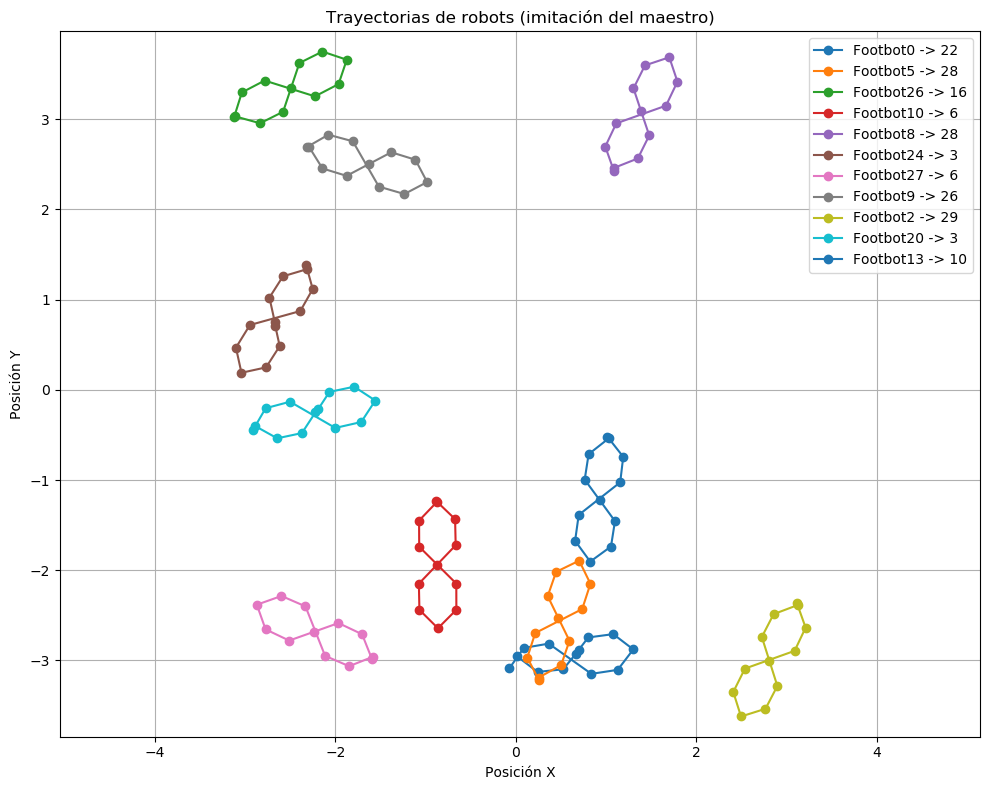

In [4]:
trayectorias = [
    (
        [
            (-0.073045172304639, -3.0888771069058),
            (0.088513587797793, -2.8608003372573),
            (0.36431357642631, -2.8133397788649),
            (0.83770384313821, -3.1482008264332),
            (1.1292325138274, -3.1040037520358),
            (1.3021775285459, -2.877651867004),
            (1.0801810823331, -2.7078340751902),
            (0.80279579976726, -2.7449223933822),
            (0.66621730433937, -2.9235436767772),
            (0.69794367656009, -2.8862006060636),
            (0.52437318834838, -3.0982131610806),
            (0.24095898725329, -3.1268149862987),
            (0.010197700465524, -2.9513970367321)
        ],
        "Footbot0 -> 22"
    ),
    (
        [
            (0.25692312305134, -3.2206948528875),
            (0.12759246722056, -2.9672903793569),
            (0.21508199301684, -2.6962050483924),
            (0.73583886933896, -2.4299982171177),
            (0.82710113453958, -2.1496235683811),
            (0.70236686847199, -1.8935249216803),
            (0.44652435629521, -2.0179641174129),
            (0.35363180999274, -2.2872458446609),
            (0.47177275393409, -2.5298644440707),
            (0.59469352256768, -2.781440445785),
            (0.50248622688997, -3.050957585151),
            (0.25359571485482, -3.189541275746)
        ],
        "Footbot5 -> 28"
    ),
    (
        [
            (-3.1221485331434, 3.0250328942912),
            (-3.0367172064536, 3.2964029997983),
            (-2.7842784326658, 3.4283739787166),
            (-2.2263021496903, 3.2531134044548),
            (-1.9646605759509, 3.3890635114606),
            (-1.8740628028748, 3.6591323869109),
            (-2.1437421655663, 3.7497610016515),
            (-2.3987693070227, 3.6228640713939),
            (-2.4909553392188, 3.3480606057792),
            (-2.5796755836304, 3.0824881707798),
            (-2.8343791226305, 2.9549429591525),
            (-3.109017444916, 3.0306114348356)
        ],
        "Footbot26 -> 16"
    ),
    (
        [
            (-0.88209517859144, -1.2324452223974),
            (-0.67311222963212, -1.4327858640832),
            (-0.66662279702672, -1.7225669823612),
            (-1.0745406266872, -2.1486308049945),
            (-1.0687755922375, -2.438427239796),
            (-0.8633103291495, -2.6428845122527),
            (-0.65899808893232, -2.4377820673798),
            (-0.65970459631609, -2.1479291562451),
            (-0.86870967733403, -1.9399492994983),
            (-1.0709768295579, -1.7391683264674),
            (-1.0724078920784, -1.4493180870229),
            (-0.87208169211908, -1.2398230651105)
        ],
        "Footbot10 -> 6"
    ),
    (
        [
            (1.0868517273125, 2.4284627540294),
            (0.99162814096634, 2.6965536235987),
            (1.1136806408782, 2.9539343941574),
            (1.664674280527, 3.1500461233337),
            (1.7916772944584, 3.4161456895792),
            (1.7013618534356, 3.6863091125035),
            (1.4314908153961, 3.5962528673064),
            (1.3043162360566, 3.3413640677133),
            (1.3898502661919, 3.0854246274081),
            (1.4789567224489, 2.81998152719),
            (1.3524308945125, 2.5647700684873),
            (1.0876103471657, 2.4597843362043)
        ],
        "Footbot8 -> 28"
    ),
    (
        [
            (-2.3256652422109, 1.3863507662141),
            (-2.2512373555644, 1.1169426454967),
            (-2.3889608583459, 0.87332332132067),
            (-2.9477763990169, 0.71854781518034),
            (-3.1023809391497, 0.46746352381039),
            (-3.041338897095, 0.1892207825301),
            (-2.7682969814929, 0.24895868399941),
            (-2.6174014542867, 0.4846463548682),
            (-2.6655055761861, 0.70429434996785),
            (-2.672036234485, 0.75386412114906),
            (-2.7312496321521, 1.0224115576098),
            (-2.5809648212468, 1.2584891167753),
            (-2.3126325671825, 1.3380456645609)
        ],
        "Footbot24 -> 3"
    ),
    (
        [
            (-1.5788446144789, -2.9568362563028),
            (-1.8480147896397, -3.0634085907557),
            (-2.1141766800911, -2.9486346506942),
            (-2.3316701923647, -2.4003428407696),
            (-2.5975443460526, -2.284903923386),
            (-2.8707287543408, -2.381818873617),
            (-2.7740862697961, -2.6547121395224),
            (-2.5124028412257, -2.779359612251),
            (-2.2345154058259, -2.6807831548655),
            (-1.9660320116771, -2.5851710893805),
            (-1.7040378142421, -2.7091640317456),
            (-1.596997579807, -2.978542235619)
        ],
        "Footbot27 -> 6"
    ),
    (
        [
            (-2.3198132353839, 2.6887962698235),
            (-2.0774468689002, 2.8280039930884),
            (-1.8071951242677, 2.7553257098566),
            (-1.5180635113506, 2.2526994309889),
            (-1.2349052238196, 2.1704575230488),
            (-0.98292798619552, 2.3033207071621),
            (-1.1131504511235, 2.5506314715371),
            (-1.3804877590867, 2.6333895654093),
            (-1.6324625015522, 2.5005347463487),
            (-1.8755575146471, 2.3719664197345),
            (-2.1431081926273, 2.4540320827293),
            (-2.2911822269872, 2.6915305526511)
        ],
        "Footbot9 -> 26"
    ),
    (
        [
            (3.11698459843, -2.3678317249356),
            (3.2124234691019, -2.6358460299789),
            (3.0905777218621, -2.8933247430168),
            (2.5397417654864, -3.0898789350805),
            (2.4105518082764, -3.3493566904899),
            (2.4963566768505, -3.6209863621061),
            (2.76768968866, -3.5354357854047),
            (2.8990903810148, -3.282699694122),
            (2.8117812513683, -3.0063080786082),
            (2.7271066095339, -2.7394182042587),
            (2.8578640124839, -2.486348697281),
            (3.1243958003716, -2.3857866153344)
        ],
        "Footbot2 -> 29"
    ),
    (
        [
            (-2.9135422940089, -0.44564290646404),
            (-2.7732842686738, -0.20388283501261),
            (-2.5029102691803, -0.13166068655218),
            (-2.0011614744817, -0.42231239016819),
            (-1.7136386131009, -0.35691751738922),
            (-1.557700780488, -0.11853013027866),
            (-1.7915158028119, 0.034607193334332),
            (-2.0654482580118, -0.022656654934653),
            (-2.1886055858294, -0.210782997853),
            (-2.2207684632049, -0.24906067714022),
            (-2.3710773380134, -0.47934353152508),
            (-2.6448606153021, -0.53731641663014),
            (-2.8895294855769, -0.4014172378788)
        ],
        "Footbot20 -> 3"
    ),
    (
        [
            (1.0150396076134, -0.51863791963577),
            (1.1907020480665, -0.74243012851944),
            (1.1569952248077, -1.025282605712),
            (0.69717491976992, -1.3866952346129),
            (0.65713985414273, -1.6737770071385),
            (0.82481659937069, -1.9040587108909),
            (1.0548978313648, -1.7367173497287),
            (1.0991714317129, -1.4553252352329),
            (0.92855512905753, -1.2210064640811),
            (0.7634562579184, -0.99485969150055),
            (0.8070139607132, -0.71335587213853),
            (1.0308724785639, -0.53718568225563)
        ],
        "Footbot13 -> 10"
    )
]
graficar_trayectorias(trayectorias) 

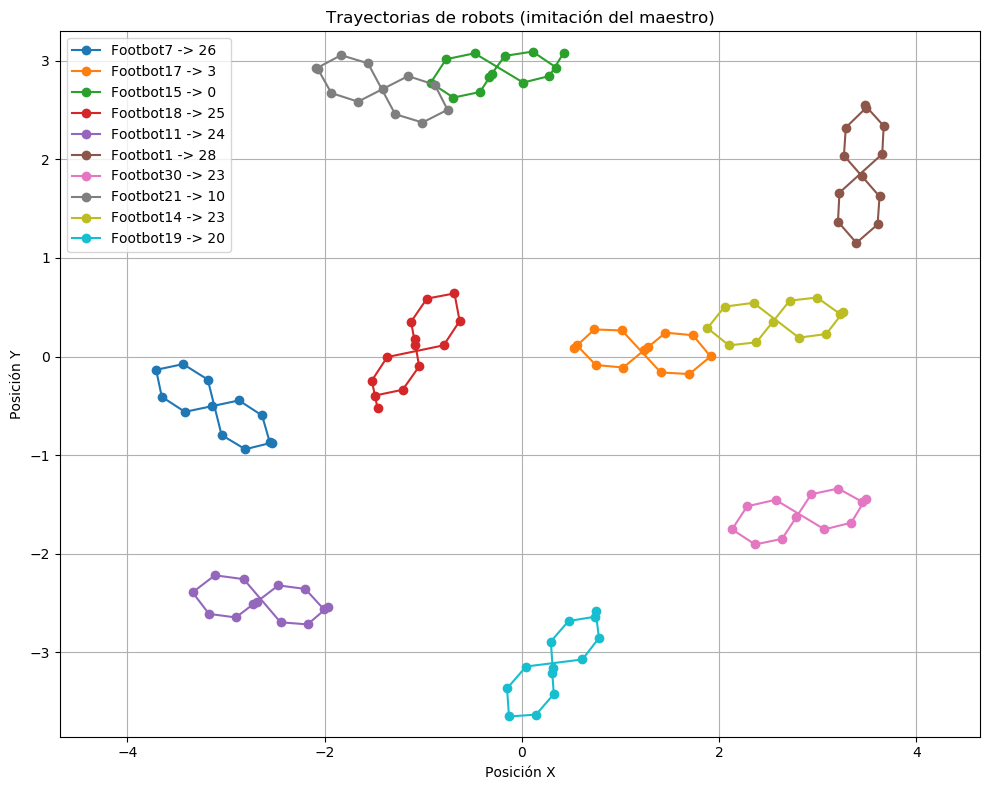

In [7]:
trayectorias = [
    (
        [
            (-2.5335147139671, -0.87290869694881),
            (-2.8047447746974, -0.9403957325582),
            (-3.044748128797, -0.79646335832862),
            (-3.1851265541927, -0.23385855610988),
            (-3.4349227951553, -0.077192716757263),
            (-3.7087667985766, -0.13490769870059),
            (-3.6512757890288, -0.40843153380242),
            (-3.4168367041752, -0.56125971779837),
            (-3.138106188184, -0.5025147329619),
            (-2.8690899757034, -0.44545969442416),
            (-2.6342559945955, -0.59768038831129),
            (-2.5569082870836, -0.86665766432075)
        ],
        "Footbot7 -> 26"
    ),
    (
        [
            (0.52979914465214, 0.084717744541007),
            (0.73497810260891, 0.27451195159405),
            (1.0146340206256, 0.26399026690723),
            (1.4086622580038, -0.16141778889916),
            (1.6980417271093, -0.17809931929786),
            (1.913371761984, 0.00066838250026025),
            (1.7349602024273, 0.21581907379403),
            (1.4563042377578, 0.24168394735852),
            (1.2794057654666, 0.094919802371415),
            (1.2398988776878, 0.064273835538158),
            (1.0285158428177, -0.11162966511875),
            (0.74979384627771, -0.08648633647741),
            (0.55593715810649, 0.11538250043927)
        ],
        "Footbot17 -> 3"
    ),
    (
        [
            (0.42359123168546, 3.0785603308769),
            (0.27955634483889, 2.8439499637854),
            (0.012793761962782, 2.7777508153775),
            (-0.47942120456396, 3.0747039380512),
            (-0.76806277174312, 3.0144384346617),
            (-0.92408624763352, 2.7761143931567),
            (-0.69451181160759, 2.6256282378228),
            (-0.42545248687471, 2.6817680868334),
            (-0.30496238347357, 2.8656643832063),
            (-0.33156271002931, 2.8306139760524),
            (-0.17293626410191, 3.0478665659795),
            (0.10846148384901, 3.0921043466238),
            (0.3485742602937, 2.9297218257107)
        ],
        "Footbot15 -> 0"
    ),
    (
        [
            (-1.4638375398439, -0.52263269090216),
            (-1.5215862549415, -0.2440553557732),
            (-1.3655529374368, -0.005737757563086),
            (-0.792951932464, 0.11334998470318),
            (-0.63082463097258, 0.35962926278967),
            (-0.68342829082584, 0.6395899902916),
            (-0.96306399833631, 0.58720320229472),
            (-1.1238314219483, 0.35205323037606),
            (-1.0805296841364, 0.12122585177246),
            (-1.088684253312, 0.17460689484725),
            (-1.041595054961, -0.10039064322715),
            (-1.2087388350621, -0.33719893281908),
            (-1.4924973419753, -0.3963879374102)
        ],
        "Footbot18 -> 25"
    ),
    (
        [
            (-1.9644347005323, -2.5382370554032),
            (-2.1733342984876, -2.7163134543712),
            (-2.4473495343628, -2.694859937621),
            (-2.8205639193926, -2.2576325904148),
            (-3.112832473838, -2.2185371986343),
            (-3.3392003256599, -2.3914512508387),
            (-3.1726978899465, -2.6096883776646),
            (-2.9002762024175, -2.646171620894),
            (-2.7215428420638, -2.509739827709),
            (-2.6840203996001, -2.4849011902399),
            (-2.4696396371768, -2.3207664017674),
            (-2.1971227204438, -2.3565313702007),
            (-2.0113557700019, -2.5591428723976)
        ],
        "Footbot11 -> 24"
    ),
    (
        [
            (3.4778634642219, 2.549522228682),
            (3.6685158960744, 2.3383542955774),
            (3.6543617547555, 2.0538523903612),
            (3.2205135131626, 1.661641344468),
            (3.2051261597127, 1.367189355075),
            (3.3920386860239, 1.1522268897903),
            (3.6068303515617, 1.3387879920786),
            (3.626670447856, 1.6229499958146),
            (3.4496231162315, 1.8266048749104),
            (3.265635474179, 2.0376701434222),
            (3.2847527064195, 2.3218816935386),
            (3.489160378463, 2.5202990060136)
        ],
        "Footbot1 -> 28"
    ),
    (
        [
            (3.48448594864, -1.4457222751356),
            (3.3400478575274, -1.6850084712582),
            (3.0684596274842, -1.752521222887),
            (2.5718374708635, -1.4531941453451),
            (2.2843239373997, -1.5186029772734),
            (2.1311354579294, -1.7528140938072),
            (2.3649619144662, -1.9059339578715),
            (2.6388900929731, -1.8486496550451),
            (2.783885790692, -1.6270108055622),
            (2.9341211628112, -1.3966755434676),
            (3.2079001104631, -1.3386822149463),
            (3.452579127737, -1.474563123733)
        ],
        "Footbot30 -> 23"
    ),
    (
        [
            (-2.0841491867229, 2.9216192713911),
            (-1.8331433798562, 3.0555458582293),
            (-1.5605088676431, 2.9730104322684),
            (-1.2848572752591, 2.4571906954707),
            (-1.0076499131772, 2.3725072398634),
            (-0.75386662744204, 2.5018872918606),
            (-0.88294699094301, 2.7554198622139),
            (-1.1538766498809, 2.8433902759676),
            (-1.4121090118435, 2.7117420458954),
            (-1.6614034480622, 2.5842575995092),
            (-1.9325559937571, 2.6715385868509),
            (-2.0713338443021, 2.9203141483834)
        ],
        "Footbot21 -> 10"
    ),
    (
        [
            (3.2566338230282, 0.44941077159625),
            (3.086351664923, 0.22777090052124),
            (2.8089186018833, 0.19104170419326),
            (2.3488705183856, 0.54400916256048),
            (2.0564705039418, 0.50604896950213),
            (1.8818503719707, 0.28734970827582),
            (2.1001731712233, 0.11283420789221),
            (2.3782866051256, 0.14399598276865),
            (2.543563386041, 0.3509527841726),
            (2.7148776159103, 0.56607236636895),
            (2.992909437837, 0.59795409038907),
            (3.2249329349476, 0.4326754678496)
        ],
        "Footbot14 -> 23"
    ),
    (
        [
            (0.7477046306685, -2.5823704349331),
            (0.78168157416609, -2.8547595191598),
            (0.61317441237613, -3.0718998868902),
            (0.042788613789447, -3.1434314960504),
            (-0.15048871680242, -3.3661268733157),
            (-0.13042431037529, -3.6502731268242),
            (0.14340554311346, -3.6310972054099),
            (0.32359378370393, -3.423547691256),
            (0.30819028059805, -3.2042341145459),
            (0.31271075207359, -3.1594692824911),
            (0.29344594252418, -2.8901650488039),
            (0.47308642262539, -2.6821412502095),
            (0.74444832418896, -2.6382835361926)
        ],
        "Footbot19 -> 20"
    )
]
graficar_trayectorias(trayectorias) 

# Fase 6: Migración de Plataforma Robótica (Versión St10 con Qupa)
MIgración desde los robots footbot a los robots Qupa, con el objetivo de usar los robots en argos3 que posteriormente se planea usar en laboratorio.

**Características del Experimento:**
* **Cambio de Plataforma:** Migración completa de los scripts de simulación y controladores de la plataforma Footbot a los nuevos robots **Qupa**.
* **Condiciones de Prueba:** Ejecución exclusiva del experimento ST10, manteniendo las mismas funcionalidades de seguimiento y prevención de colisiones.


## St10 (Prueba Qupa)  
    COMPORTAMIENTO  : TRIANGULO
    ROBOT           : QUPA


    NOTA:
        Prueba inicial de la versión de código St10 migrada a los nuevos robots Qupa.
        (Mismas funcionalidades de seguimiento para evitar perder de vista al maestro o evitar colisiones).
        31 footbot en la arena.


    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Qupa/Argos/St.argos"   
        LUA_SCRIPT          = "experiments/Qupa/Controller/St10.lua" 

<video width="640" height="480" controls>
  <source src="Robots/Qupa/St10/video_dem/St10.mp4" type="video/mp4">
</video>

    Otros:
    
        Arbol de transmisión del comportamiento:
<img src="Robots/Qupa/St10/Imitation_chain/A1.png" width="640" height="480" alt="Descripción de la imagen">

        Comportamiento aprendido:
<video width="640" height="480" controls>
  <source src="Robots/Qupa/St10/Pattern/patrones_imitacion.mp4" type="video/mp4">
</video>


# Fase 7: Actualizaciones del Algoritmo - Reconstrucción y Aprendizaje Activo (Versiones Tr y Ks)
Evolución de la lógica de aprendizaje, pasando de la observación simple a la recolección de datos distribuida y posicionamiento inteligente.

**Características del Experimento:**
* **Múltiples Maestros (Algoritmo Tr):** El robot aprendiz, manteniéndose en un estado estático, obtiene y fusiona información parcial de múltiples robots maestros para reconstruir el comportamiento global. Además, demuestra la capacidad de diferenciar múltiples comportamientos simultáneos en la arena.
* **Aprendizaje Activo (Algoritmo Ks):** Implementación de "Active Learning". El robot aprendiz abandona la postura estática para buscar activamente ubicaciones estratégicas, calculando posiciones de equidistancia entre los maestros para maximizar la calidad de la información recolectada.

## Tr7  
    COMPORTAMIENTO  :   
    ROBOT           : QUPA


    NOTA:
        Robot aprendiz estático durante la etapa de observación.
        El aprendiz obtiene información de múltiples maestros para reconstruir el comportamiento global uniendo información parcial.
        Capacidad de diferenciar múltiples comportamientos simultáneos en la arena (siempre y cuando sean suficientemente diferenciables entre sí).


    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Qupa/Argos/Tr.argos"   
        LUA_SCRIPT          = "experiments/Qupa/Controller/Tr7.lua" 

<video width="640" height="480" controls>
  <source src="Robots/Qupa/Tr7/video_dem/Tr7.mp4" type="video/mp4">
</video>


    Vista en matplot
<video width="640" height="480" controls>
  <source src="Robots/Qupa/Tr7/Trajectory/Tr7.mp4" type="video/mp4">
</video>

## Ks1    
    COMPORTAMIENTO  :   
    ROBOT           : QUPA


    NOTA:
        Implementación de Active Learning en el robot aprendiz.
        El robot ya no se queda estático; se mueve activamente a posiciones estratégicas para obtener más información.
        Primer acercamiento: el robot busca posicionarse con equidistancia entre los maestros que observa para recolectar información óptima de todos ellos.


    Simulación: script -> run_sim.py: 
        ARGOS_FILE          = "experiments/Qupa/Argos/Ks.argos"   
        LUA_SCRIPT          = "experiments/Qupa/Controller/Ks1/Ks1.lua" 

<video width="640" height="480" controls>
  <source src="Robots/Qupa/Ks1/video_dem/Ks1.mp4" type="video/mp4">
</video>

    Vista en matplot
    
<video width="640" height="480" controls>
  <source src="Robots/Qupa/Ks1/Trajectory/Ks1.mp4" type="video/mp4">
</video>

    Comportamientos aprendidos:
<img src="Robots/Qupa/Ks1/Calidad_Imitacion/Qi_1.png" width="700" height="250" alt="Descripción de la imagen">
<img src="Robots/Qupa/Ks1/Calidad_Imitacion/Qi_2.png" width="700" height="250" alt="Descripción de la imagen">

